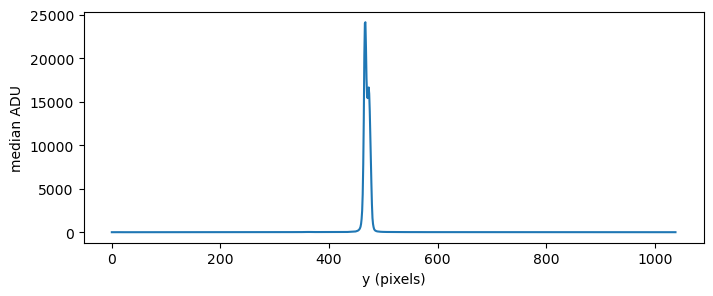

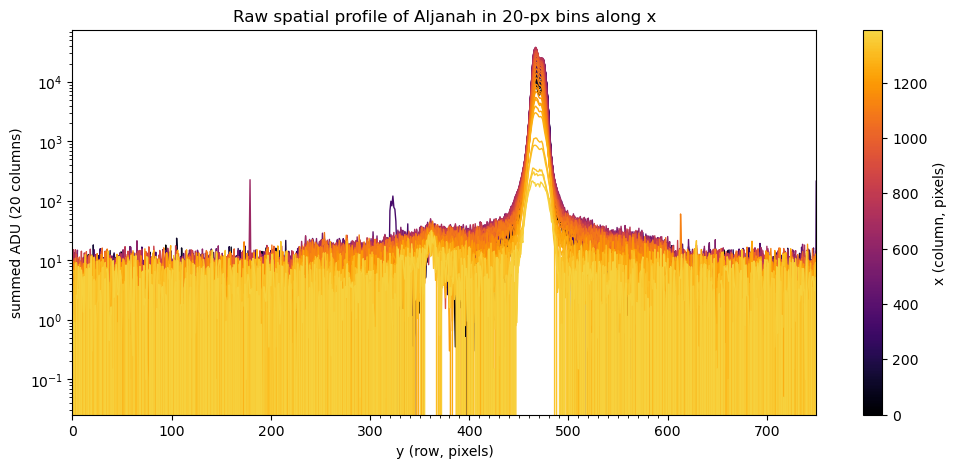

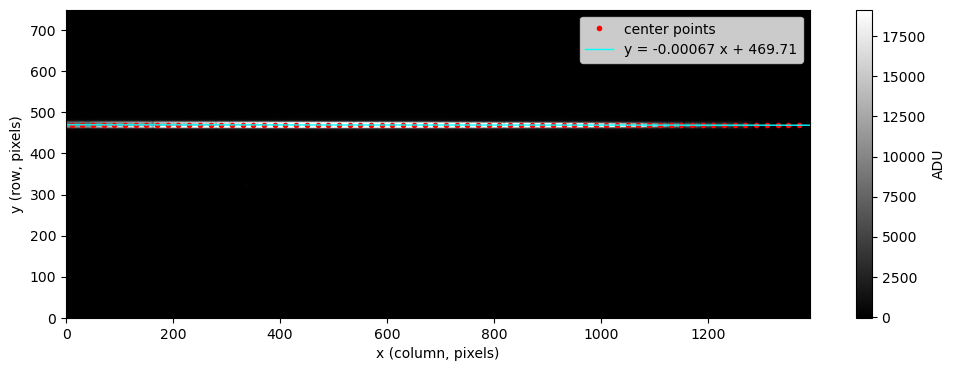

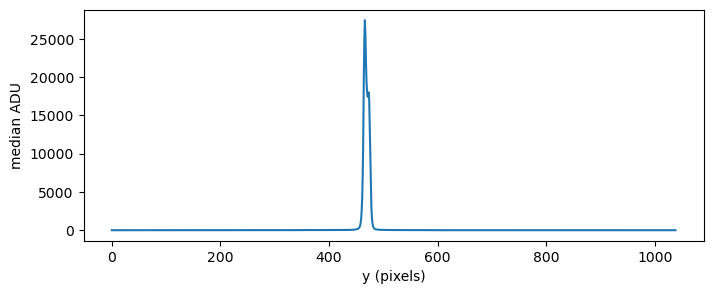

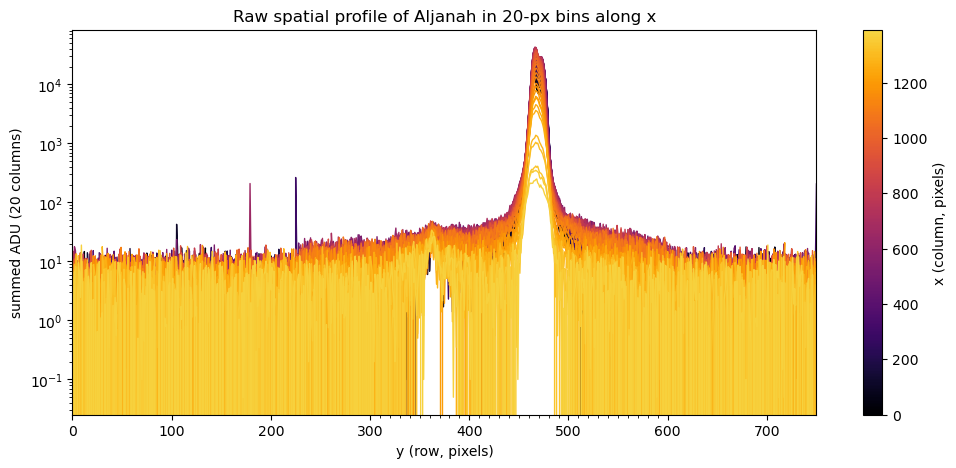

...

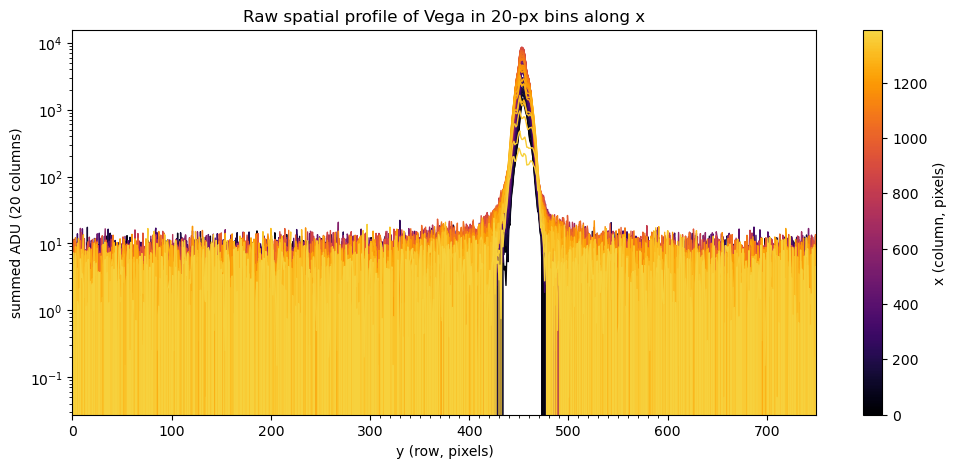

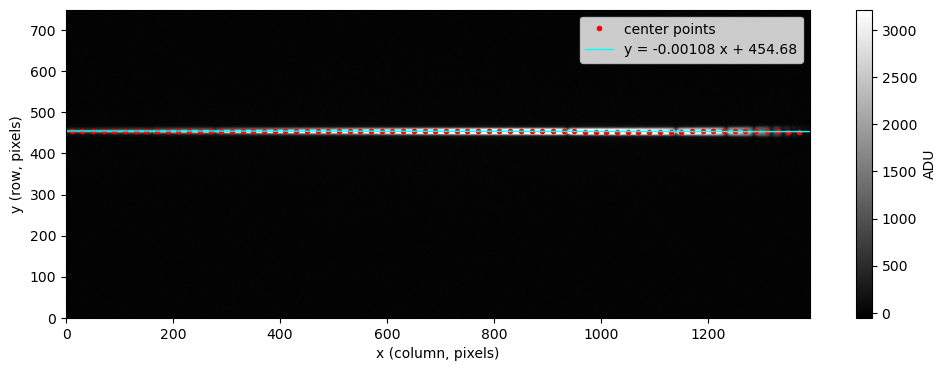

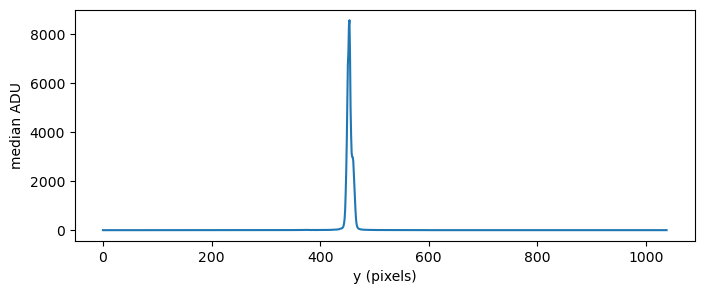

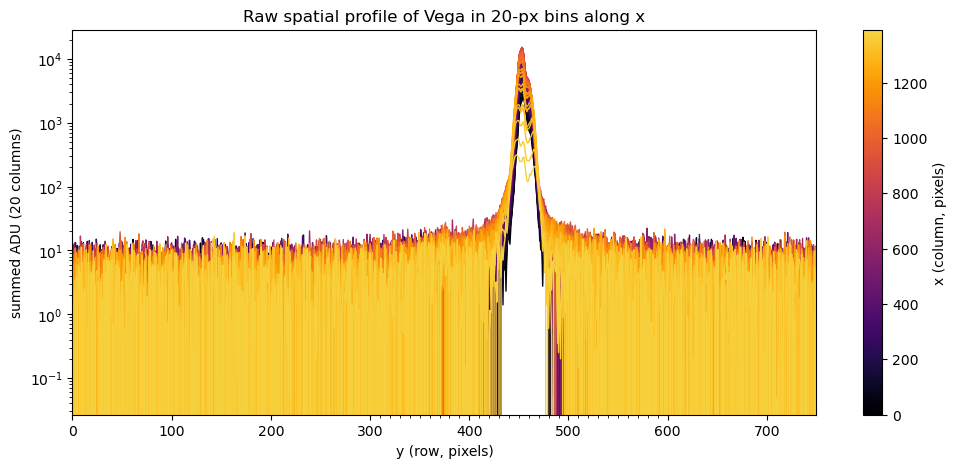

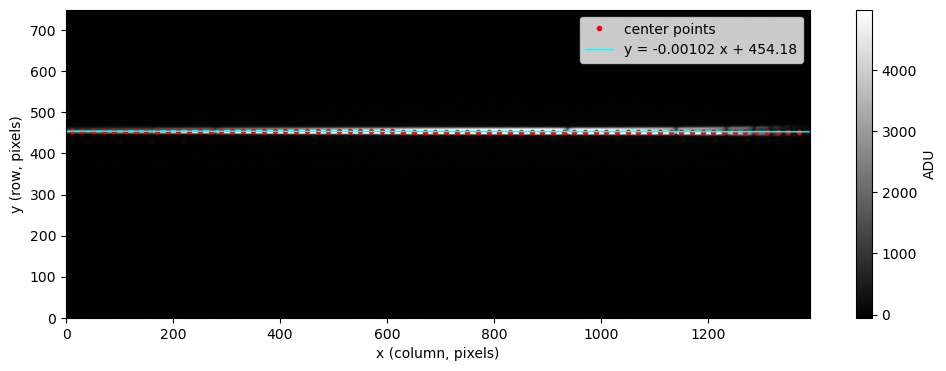

In [1]:
# Read in fits file using astropy
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.optimize import curve_fit

def gaussian(y, amp, mu, sigma, offset):
    return amp * np.exp(-0.5 * ((y - mu) / sigma)**2) + offset

def least_squares(x_arr, y_arr, N):
    """
    Return a tuple of gradient (m) and constant (c) for linear regression using values from arrays x_arr and y_arr.
    Both arrays contain N entries.
    """    
    x_arr2 = x_arr ** 2
    xy_arr = x_arr * y_arr
    
    sum_x = np.sum(x_arr)
    sum_y = np.sum(y_arr)
    sum_x2 = np.sum(x_arr2)
    sum_xy = np.sum(xy_arr)
    
    det = (N * sum_x2 - sum_x ** 2)**(-1)

    m = det * (sum_xy * N - sum_y * sum_x)
    c = det * (sum_y * sum_x2 - sum_xy * sum_x)

    return (m, c)


objs = ["aljanah", "caph", "moon", "scheat", "vega"]
darks = ["30s", "20s", "1s", "30s", "3s"] # dark frames in the order that we need them for subtraction

avg_data = [] # average science frame, per object
std_data = [] # standard deviation per pixel of average science frame, per object

avg_dark = []
std_dark = []

dark_sub_spectra = []
sky_frames_top = []
sky_frames_bottom = []

# load dark frames and average them
for dark in darks:
    raw_dark = [] # array for storing raw fits data from all trials of each object (iterated)
    with open(f"cal/dark/{dark}/files.txt") as f:
        for file in f.readlines():
            hdul = fits.open(f"cal/dark/{dark}/{file}".strip())
            raw_dark.append(hdul[0].data.astype(float)) # take raw data
            hdul.close()
    
    raw_dark = np.array(raw_dark) # convert to numpy array for average calculation
    avg_dark.append(np.median(raw_dark, axis=0))
    std_dark.append(np.std(raw_dark, axis=0))

avg_dark = np.array(avg_dark)
std_dark = np.array(std_dark)

i = 0

for obj in objs:
    slopes = []
    intercepts = []
    raw_data = [] # array for storing raw fits data from all trials of each object (iterated)
    
    with open(f"{obj}/files.txt") as f:
        for file in f.readlines():
            hdul = fits.open(f"{obj}/{file}".strip())
            raw_data.append(hdul[0].data.astype(float)) # take raw data
            hdul.close()
    
    raw_data = np.array(raw_data) # convert to numpy array for average calculation
    
    raw_data -= avg_dark[i] # dark subtraction

    for data in raw_data:
        row_prof = np.median(data, axis=1)
        y = np.arange(data.shape[0])

        fig, ax = plt.subplots(figsize=(8, 3))
        ax.plot(y, row_prof, label='data')

        ax.set_xlabel('y (pixels)')
        ax.set_ylabel('median ADU')
        plt.show()

        # Chunk original data rows into bins of 20 pixels, see if there's a drift 
        from matplotlib.colors import ListedColormap

        bin_width = 20 # how many pixels to average
        nrows, ncols = data.shape
        nbins = ncols // bin_width  

        # 1) chunk: (rows, nbins, bin_width)
        chunks = data[:, :nbins * bin_width].reshape(nrows, nbins, bin_width)

        # 2) sum the pixels in each bin -> (rows, nbins)
        binned_sum = chunks.sum(axis=2)/bin_width   # average ADU per column in each bin

        # 3) Calculate bin centers 
        x_centres = (np.arange(nbins) + 0.5) * bin_width

        cmap = ListedColormap(plt.cm.inferno(np.linspace(0, 0.9, 256)))   # drop the near-white end
        norm = plt.Normalize(0, ncols)
        fig, ax = plt.subplots(figsize=(12, 5))
        for i in range(nbins):
            ax.semilogy(y, binned_sum[:, i], color=cmap(norm(x_centres[i])), lw=1)

        ax.set(xlabel='y (row, pixels)', ylabel=f'summed ADU ({bin_width} columns)',
               title=f'Raw spatial profile of {obj.capitalize()} in {bin_width}-px bins along x')
        fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax, label='x (column, pixels)');

        ax.set_xlim(0,750)
        ax.set_xticks(np.arange(300, 600, 10), minor=True)

        # Fit a Gaussian to each binned profile
        y_centres = np.full(nbins, np.nan)
        y_errs = np.full(nbins, np.nan)
        for i in range(nbins):
            prof = binned_sum[:, i]
            p0 = [prof.max() - np.median(prof), np.argmax(prof), 5, np.median(prof)] # Initial guess to give optimizer
            try:
                popt, pcov = curve_fit(gaussian, y, prof, p0=p0)
                y_centres[i], y_errs[i] = popt[1], np.sqrt(pcov[1, 1])
            except RuntimeError:                         
                pass

        # Fit a line to the centers 
        # good = np.isfinite(y_centres)
        
        # removing non-clean y-centres (nan values, outliers)
        filtered_y_centres = []
        filtered_x_centres = []
        
        for i in range(len(y_centres)):
            if np.isfinite(y_centres[i]) and 400 < y_centres[i] < 500:
                filtered_y_centres.append(y_centres[i])
                filtered_x_centres.append(x_centres[i])
                
        filtered_y_centres = np.array(filtered_y_centres)
        filtered_x_centres = np.array(filtered_x_centres)
        
        slope, intercept = least_squares(filtered_x_centres, filtered_y_centres, len(filtered_x_centres))
        
        slopes.append(slope)
        intercepts.append(intercept)
        
        x_line = np.arange(ncols)

        # Overplot the fitted centres on the image
        fig, ax = plt.subplots(figsize=(12, 4))
        vmin, vmax = np.percentile(data, [1, 99.5])
        im = ax.imshow(data, origin='upper', cmap='gray', vmin=vmin, vmax=vmax, aspect='auto')
        ax.plot(filtered_x_centres, filtered_y_centres, marker='o',ls='none', ms=3, color='red', label='center points')
        
        ax.plot(x_line, slope * x_line + intercept, color='cyan', lw=1,
                label=f'y = {slope:.5f} x + {intercept:.2f}')
        ax.set(xlabel='x (column, pixels)', ylabel='y (row, pixels)')
        ax.legend(loc='upper right')
        fig.colorbar(im, label='ADU')

        ax.set_ylim(0,750)

        plt.show()
        
    # By eye guess what aperture halfwidth is
    # (note that the moon uses an arbitrary 30 pixels because of the fact that it covered the entire slit -> no proper HW)
    aperture_halfwidths = [10, 15, 30, 15, 10] # in pixels, for each object

    # take some sky frames to median combine, that we'll subtract from the median dark-subtracted frame
    sky_top = []
    sky_bottom = []
    
    # select data from each frame using the aperture halwidth
    x_cols = np.arange(ncols)
    selected_data = []
    for i in range(len(raw_data)):
        # Calculate trace 
        trace_y = slopes[i] * x_cols + intercepts[i]
        trace_sky_top = slopes[i] * x_cols + intercepts[i] + 2*aperture_halfwidths[i]
        trace_sky_bottom = slopes[i] * x_cols + intercepts[i] - 2*aperture_halfwidths[i]
        
        selected_data.append(np.abs(y[:, None] - trace_y[None, :]) <= aperture_halfwidths[i])
        sky_top.append(np.abs(y[:, None] - trace_sky_top[None, :]) <= aperture_halfwidths[i])
        sky_bottom.append(np.abs(y[:, None] - trace_sky_top[None, :]) <= aperture_halfwidths[i])

    selected_data = np.array(selected_data)
    
    sky_top = np.array(sky_top)
    sky_bottom = np.array(sky_bottom)
    
    dark_sub_spectra.append(np.where(selected_data, data, 0).sum(axis=1)) # zero out data outside of aperture
    sky_frames_top.append(np.where(sky_top, data, 0).sum(axis=1))
    sky_frames_bottom.append(np.where(sky_bottom, data, 0).sum(axis=1))
    
    i += 1

With that, let's median combine each spectrum, and subtract our sky frames. We then need to divide by our normalized flat frame, and calibrate using our Ne/Ar emission spectrum.

In [2]:
# median combine selected spectra
dark_sub_spectra = np.array(dark_sub_spectra)

median_spectra = []
median_sky_top = []
median_sky_bottom = []

for obj_spectra in dark_sub_spectra:
    median_spectra.append(np.median(obj_spectra, axis=0))

for sky_top in sky_frames_top:
    median_sky_top.append(np.median(sky_top, axis=0))
    
for sky_bottom in sky_frames_bottom:
    median_sky_bottom.append(np.median(sky_bottom, axis=0))

median_sky_top = np.array(median_sky_top)
median_sky_bottom = np.array(median_sky_bottom)

median_sky_stack = np.stack([median_sky_top, median_sky_bottom])

median_sky = np.median(median_sky_stack, axis=0)

median_spectra = np.array(median_spectra)

nosky_spectra = median_spectra - median_sky # science - median sky - dark

flat_reduced = 0 # flag to determine if flat division has occurred (to avoid cell doing this division running twice+)

We can plot our spectra as a sanity check:

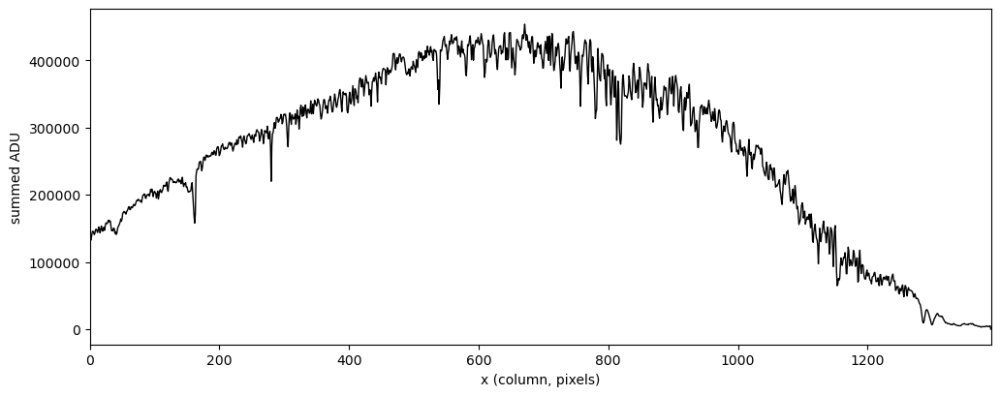

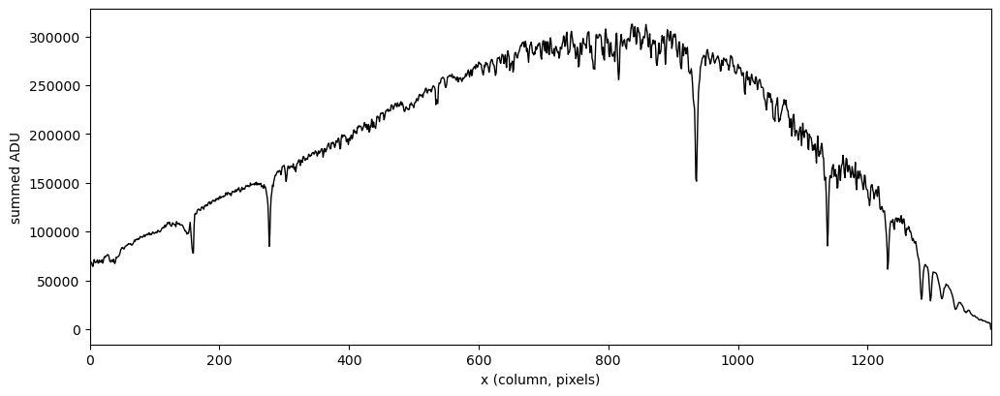

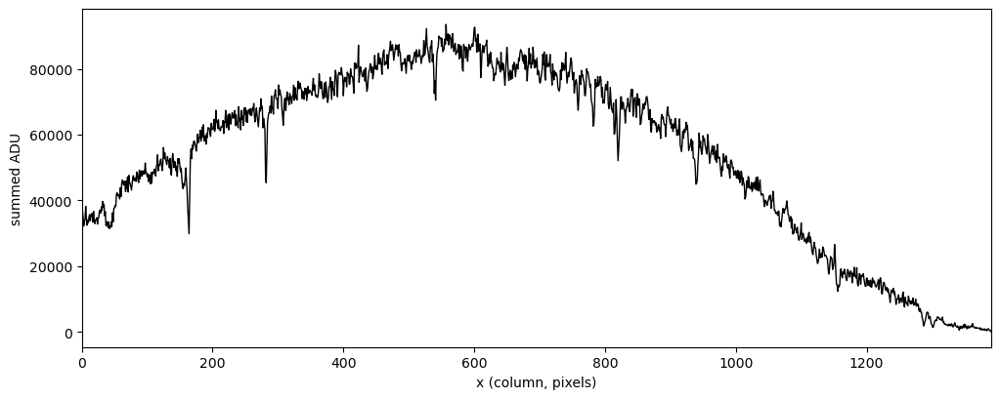

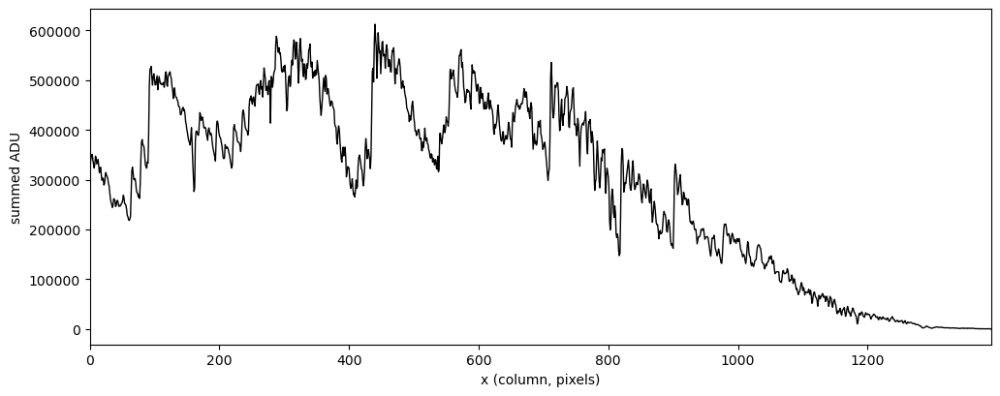

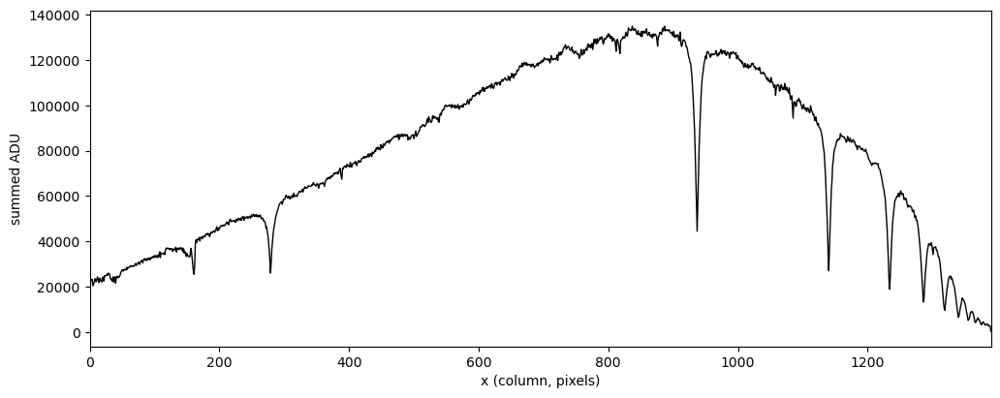

In [3]:
for spectrum in nosky_spectra:
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(x_cols, spectrum, color='k', lw=1, label=f"")
    ax.set(xlabel='x (column, pixels)', ylabel=f"summed ADU", xlim=(0, ncols - 1))

Now, let's get our flat frames ready. We also need the 10s dark frame to subtract from it.

In [4]:
dark10 = []
flats = []

##########
# DARK FRAMES
##########
with open("cal/dark/10s/files.txt") as f:
    for file in f.readlines():
        hdul = fits.open(f"cal/dark/10s/{file}".strip())
        dark10.append(hdul[0].data.astype(float)) # take raw data
        hdul.close()
    
    dark10 = np.array(dark10) # convert to numpy array for median calculation
    med_dark10 = np.median(dark10, axis=0)
    std_dark10 = np.std(dark10, axis=0)
    
    med_dark10 = np.array(med_dark10)
    std_dark10 = np.array(std_dark10)

##########
# FLAT FRAMES
##########
with open("cal/w/files.txt") as f:
    for file in f.readlines():
        hdul = fits.open(f"cal/w/{file}".strip())
        flats.append(hdul[0].data.astype(float)) # take raw data
        hdul.close()
    
    flats = np.array(flats) # convert to numpy array for median calculation
    med_flat = np.median(flats, axis=0)
    std_flat = np.std(flats, axis=0)
    
    med_flat = np.array(med_flat)
    std_flat = np.array(std_flat)

# dark-subtract the median flat frame
dark_sub_flat = med_flat - med_dark10

Same process as other frames: check if it's straight

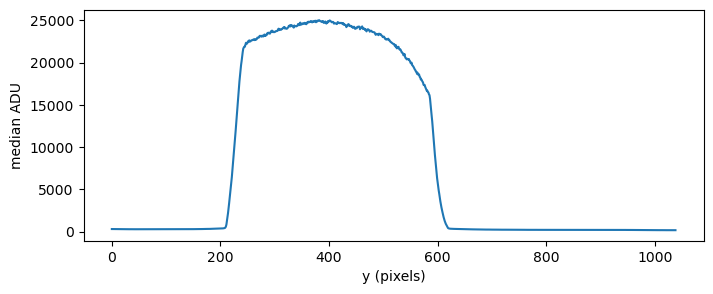

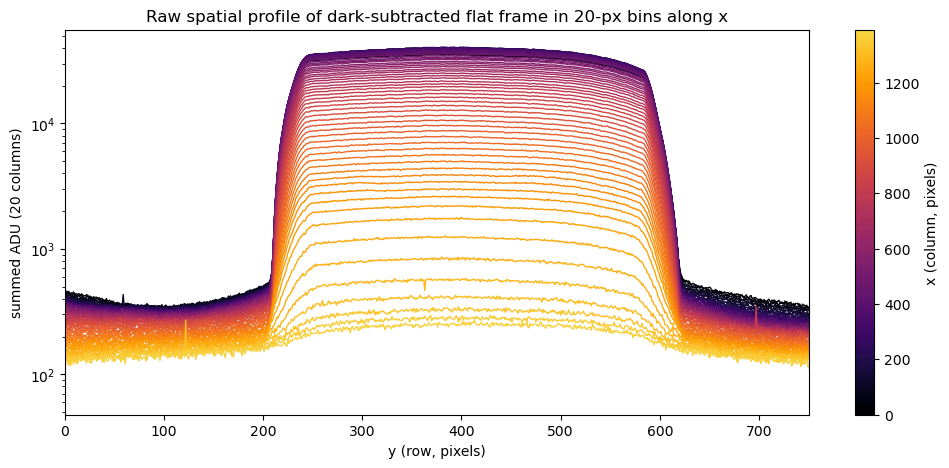

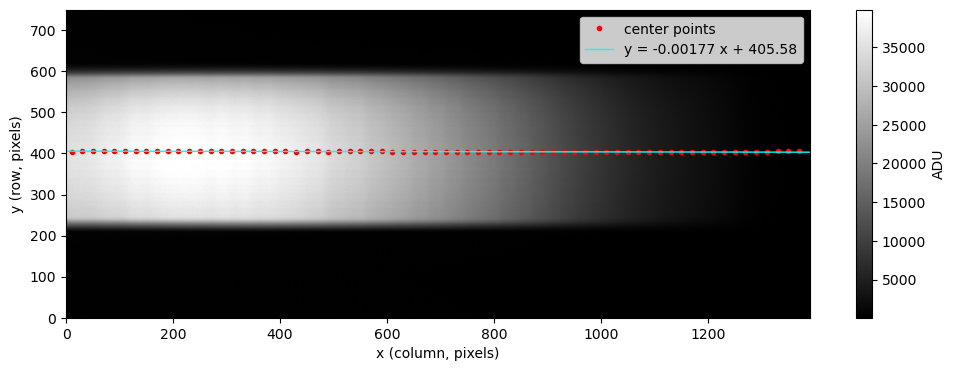

In [5]:
row_prof = np.median(dark_sub_flat, axis=1)
y = np.arange(dark_sub_flat.shape[0])

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(y, row_prof, label='data')

ax.set_xlabel('y (pixels)')
ax.set_ylabel('median ADU')
plt.show()

# Chunk original data rows into bins of 20 pixels, see if there's a drift 
from matplotlib.colors import ListedColormap

bin_width = 20 # how many pixels to average
nrows, ncols = dark_sub_flat.shape
nbins = ncols // bin_width  

# 1) chunk: (rows, nbins, bin_width)
chunks = dark_sub_flat[:, :nbins * bin_width].reshape(nrows, nbins, bin_width)

# 2) sum the pixels in each bin -> (rows, nbins)
binned_sum = chunks.sum(axis=2)/bin_width   # average ADU per column in each bin

# 3) Calculate bin centers 
x_centres = (np.arange(nbins) + 0.5) * bin_width

cmap = ListedColormap(plt.cm.inferno(np.linspace(0, 0.9, 256)))   # drop the near-white end
norm = plt.Normalize(0, ncols)
fig, ax = plt.subplots(figsize=(12, 5))
for i in range(nbins):
    ax.semilogy(y, binned_sum[:, i], color=cmap(norm(x_centres[i])), lw=1)

ax.set(xlabel='y (row, pixels)', ylabel=f'summed ADU ({bin_width} columns)',
       title=f'Raw spatial profile of dark-subtracted flat frame in {bin_width}-px bins along x')
fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax, label='x (column, pixels)');

ax.set_xlim(0,750)

# Fit a Gaussian to each binned profile
y_centres = np.full(nbins, np.nan)
y_errs = np.full(nbins, np.nan)
for i in range(nbins):
    prof = binned_sum[:, i]
    p0 = [prof.max() - np.median(prof), np.argmax(prof), 5, np.median(prof)] # Initial guess to give optimizer
    try:
        popt, pcov = curve_fit(gaussian, y, prof, p0=p0)
        y_centres[i], y_errs[i] = popt[1], np.sqrt(pcov[1, 1])
    except RuntimeError:                         
        pass

# Fit a line to the centers 
# good = np.isfinite(y_centres)

# removing non-clean y-centres (nan values, outliers)
filtered_y_centres = []
filtered_x_centres = []

for j in range(len(y_centres)):
    if np.isfinite(y_centres[j]) and 300 < y_centres[j] < 500:
        filtered_y_centres.append(y_centres[j])
        filtered_x_centres.append(x_centres[j])

filtered_y_centres = np.array(filtered_y_centres)
filtered_x_centres = np.array(filtered_x_centres)


flat_slope, flat_intercept = least_squares(filtered_x_centres, filtered_y_centres, len(filtered_x_centres))

x_line = np.arange(ncols)

# Overplot the fitted centres on the image
fig, ax = plt.subplots(figsize=(12, 4))
vmin, vmax = np.percentile(dark_sub_flat, [1, 99.5])
im = ax.imshow(dark_sub_flat, origin='upper', cmap='gray', vmin=vmin, vmax=vmax, aspect='auto')
ax.plot(filtered_x_centres, filtered_y_centres, marker='o',ls='none', ms=3, color='red', label='center points')

ax.plot(x_line, flat_slope * x_line + flat_intercept, color='cyan', lw=1,
        label=f'y = {flat_slope:.5f} x + {flat_intercept:.2f}')
ax.set(xlabel='x (column, pixels)', ylabel='y (row, pixels)')
ax.legend(loc='upper right')
fig.colorbar(im, label='ADU')

ax.set_ylim(0,750)

plt.show()

Here again: aperture halfwidth and estimations from there. No need for sky frames, as the tungsten lamp used for the flats is directly inside the spectrograph.

In [6]:
# By eye guess what aperture halfwidth is
flat_halfwidth = 150 # in pixels, guarantees we don't have negative values because of dark subtraction

# select data from each frame using the aperture halwidth
x_cols = np.arange(ncols)

# Calculate trace 
trace_y = flat_slope * x_cols + flat_intercept
selected_flat_data = np.abs(y[:, None] - trace_y[None, :]) <= flat_halfwidth

selected_flat_data = np.array(selected_flat_data)

flat_spectrum = np.where(selected_flat_data, dark_sub_flat, 0).sum(axis=0) # zero out data outside of aperture

# normalize the flat
flat_med = np.median(flat_spectrum)

master_flat = flat_spectrum / flat_med

Sanity check: plot the master flat:

[Text(0.5, 0, 'x (column, pixels)'), Text(0, 0.5, 'summed ADU'), (0.0, 1390.0)]

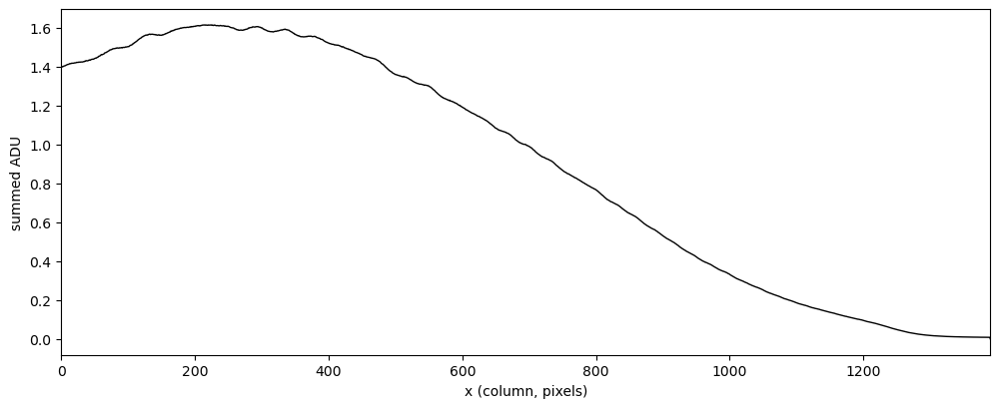

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(x_cols, master_flat, color='k', lw=1, label=f"")
ax.set(xlabel='x (column, pixels)', ylabel=f"summed ADU", xlim=(0, ncols - 1))

Looking good! Now let's divide each of our dark-and-sky-subtracted science frames by this spectrum to get spectra that are ready for calibration!

In [8]:
if flat_reduced == 0:
    for spectrum in nosky_spectra:
        spectrum /= master_flat
    flat_reduced = 1

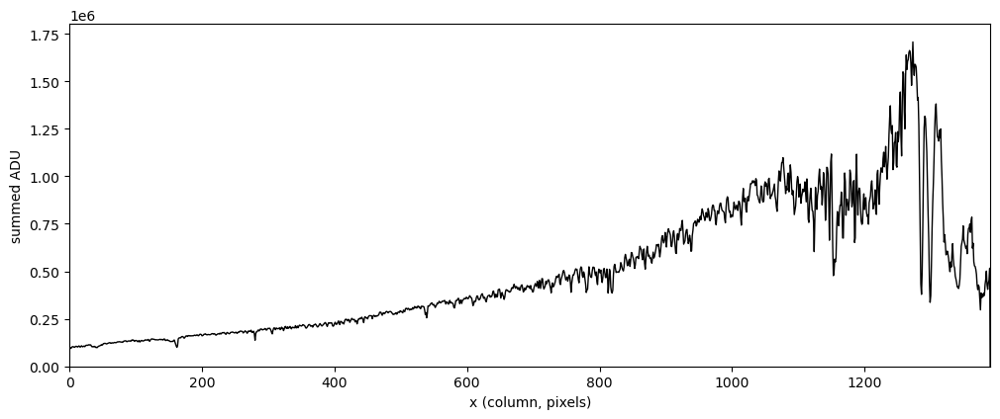

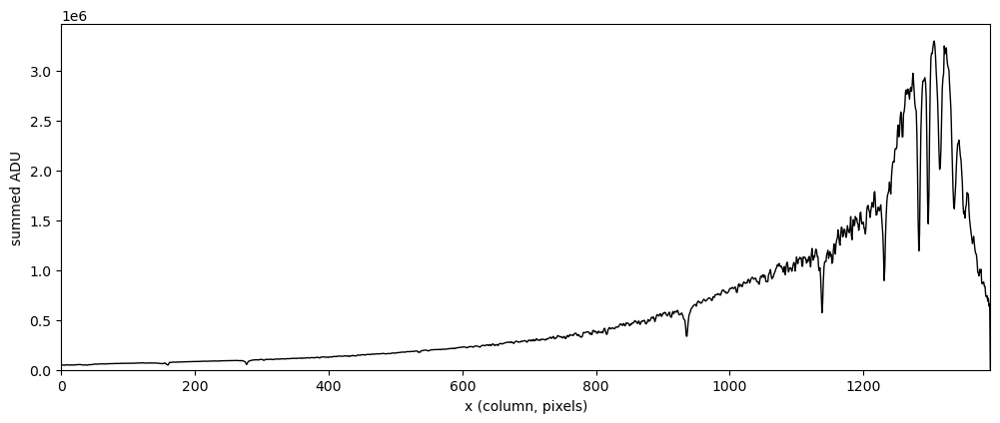

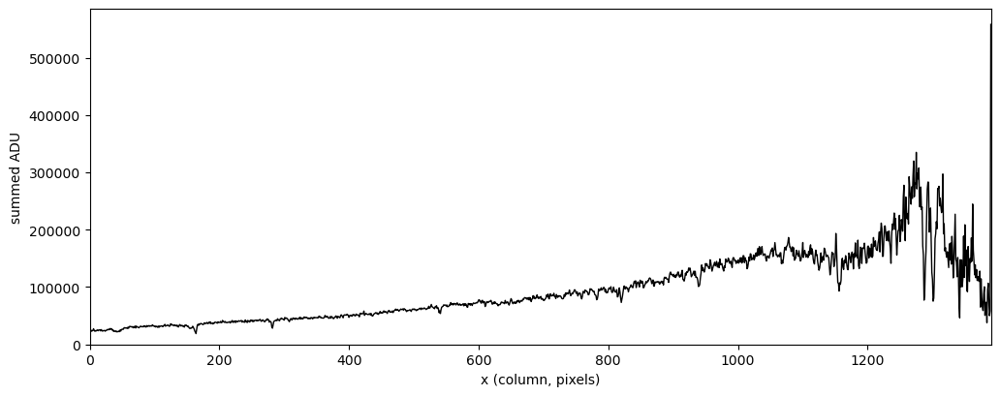

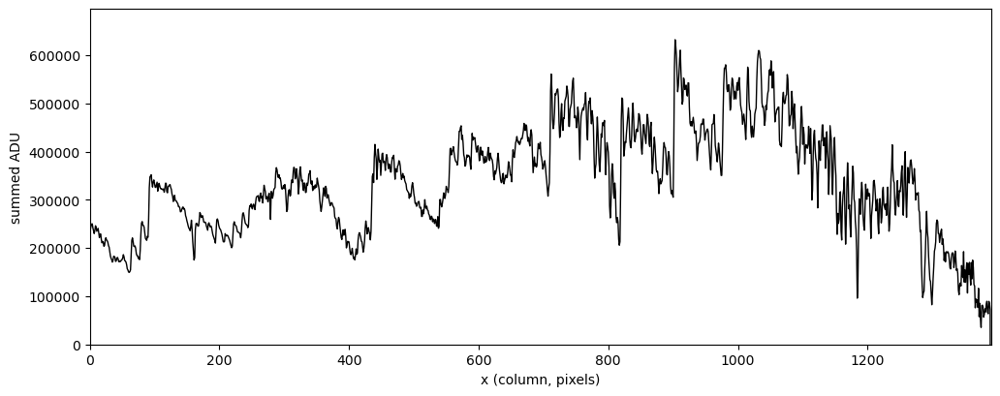

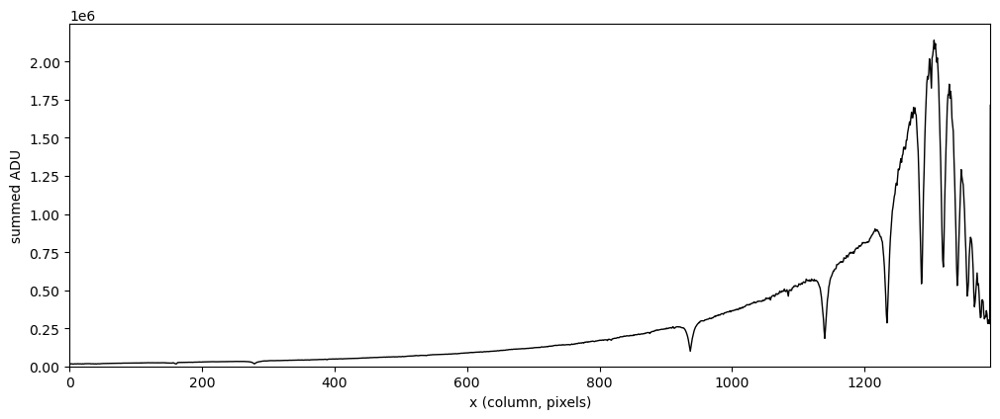

In [9]:
for spectrum in nosky_spectra:
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(x_cols, spectrum, color='k', lw=1, label=f"")
    ax.set(xlabel='x (column, pixels)', ylabel=f"summed ADU", xlim=(0, ncols - 1))
    ax.set_ylim(0)

Now, let's calibrate! We already have a calibration function from Ne_calibration.ipynb, which will be copied over to here! We'll very quickly need to install ipynb and import the other notebook (ignore the output from importing). We can then use `get_calibration` to get the calibration function we obtained from that notebook!

In [10]:
!pip install ipynb

Filename: cal/ne/Neon10_2026-10-20_21-00-15__-10.43_10.00s_0000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      40   (1391, 1039)   int16 (rescales to uint16)   
None
Filename: cal/ne/Neon10_2026-10-20_21-00-54__-9.62_10.00s_0000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      40   (1391, 1039)   int16 (rescales to uint16)   
None
Filename: cal/ne/Neon10_2026-10-20_21-01-29__-9.70_10.00s_0000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      40   (1391, 1039)   int16 (rescales to uint16)   
None
Filename: cal/dark/10s/dark10_2026-09-12_04-52-55__-10.03_10.00s_0000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      41   (1391, 1039)   int16 (rescales to uint16)   
None
Filename: cal/dark/10s/dark10_2026-09-12_04-53-07__-10.03_10.00s_0000.fits
No.    Name      Ver    Type 

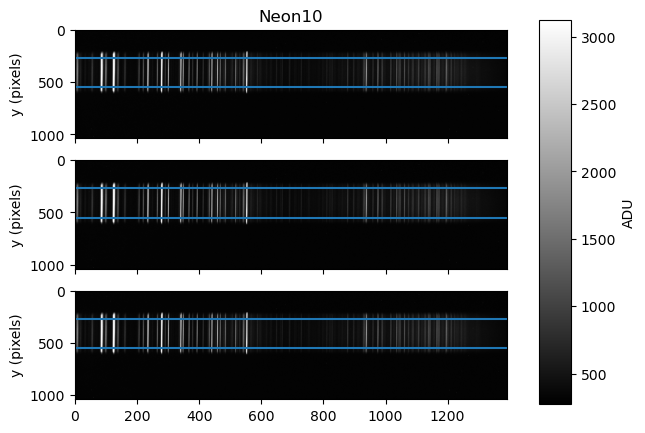

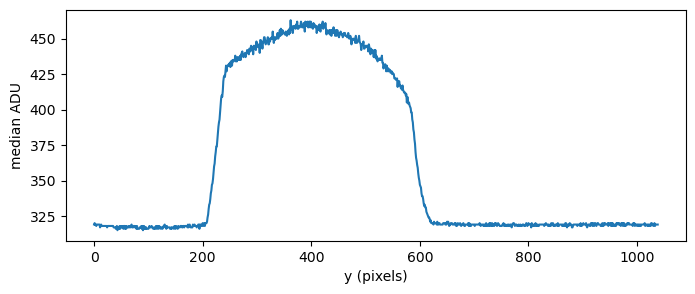

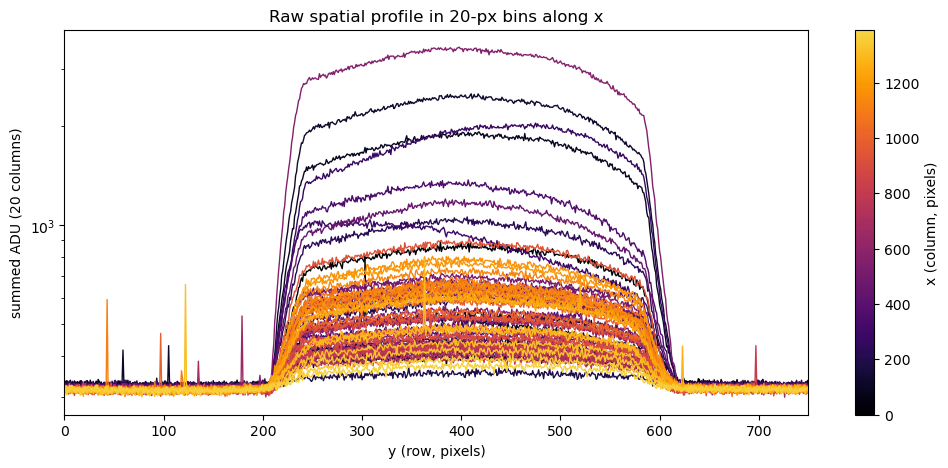

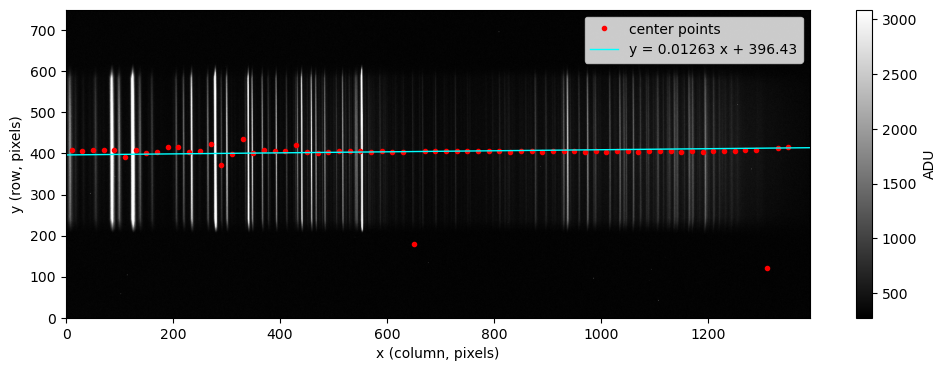

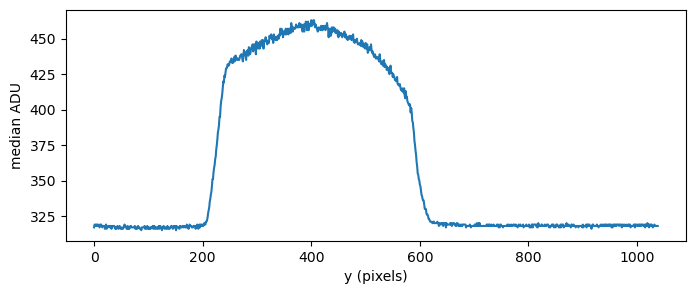

/home/jovyan/AST326/lab2/32/Ne_cal_tests.ipynb:131: OptimizeWarning: Covariance of the parameters could not be estimated
  "    \n",


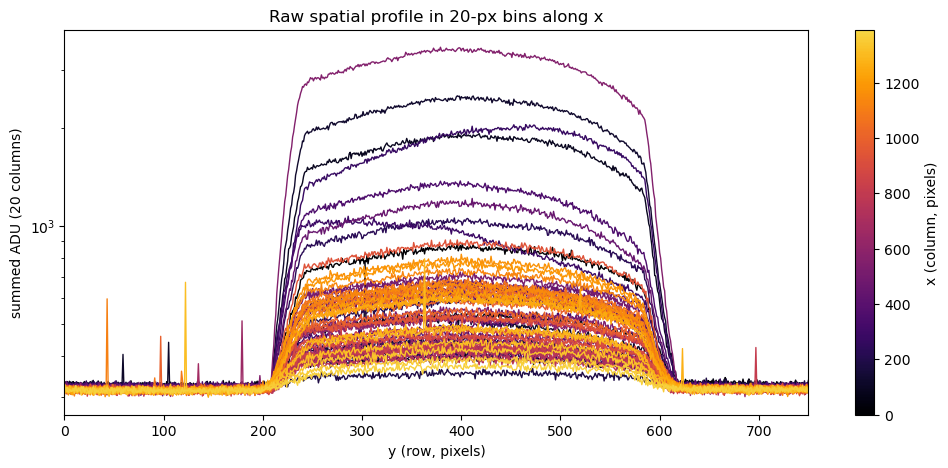

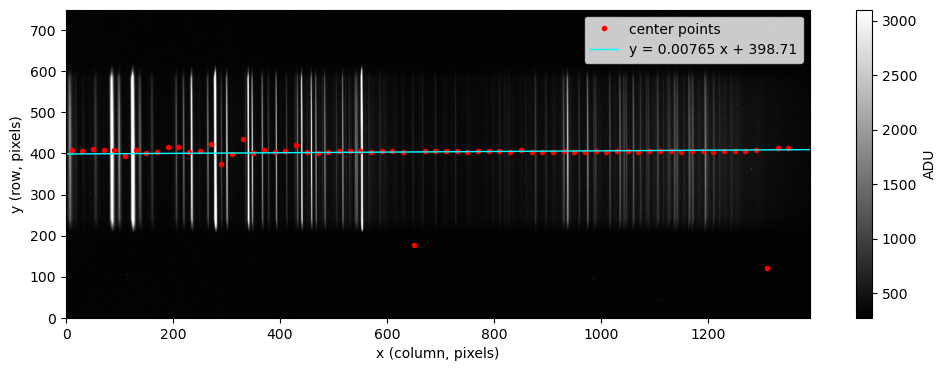

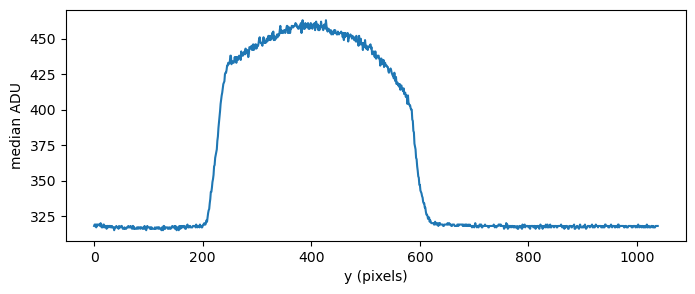

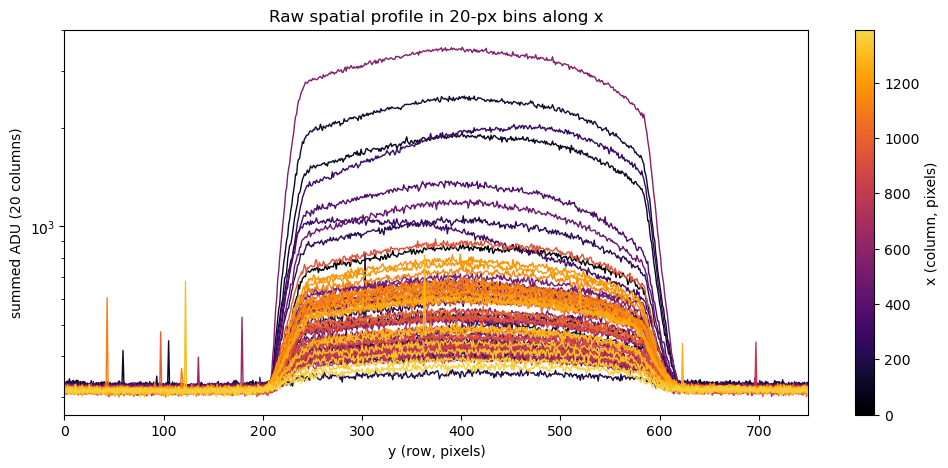

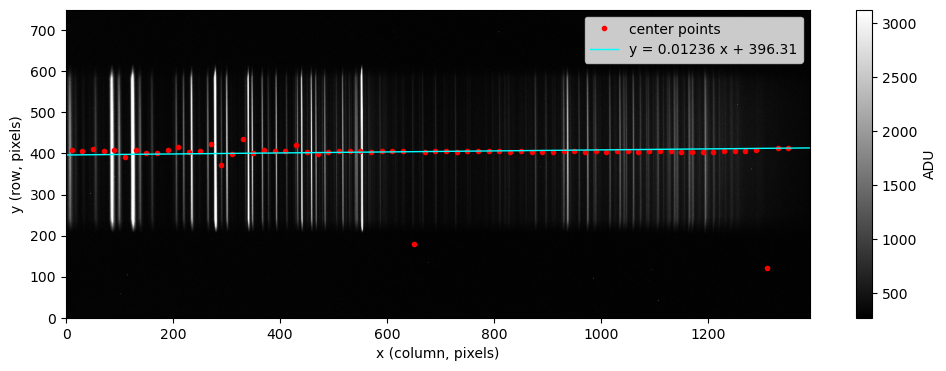

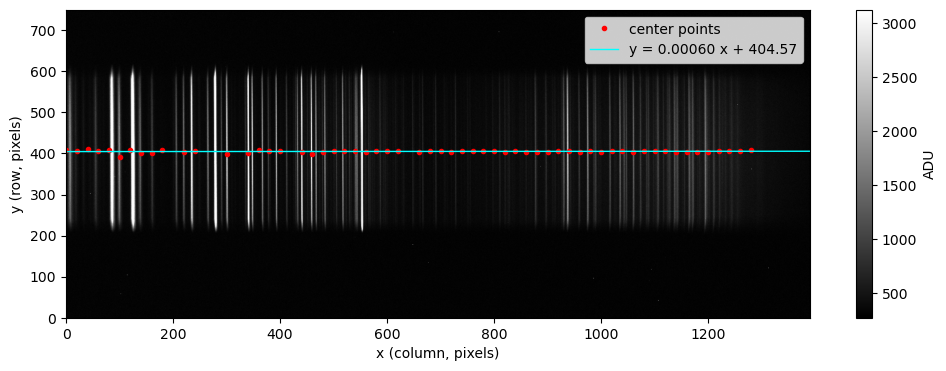

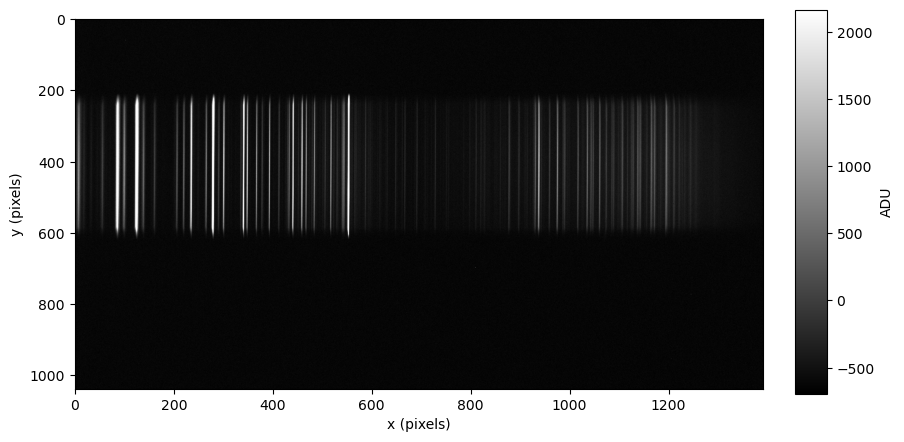

Number of peaks above 180000 ADUs: 3
Locations:
[np.int64(124), np.int64(279), np.int64(553)]


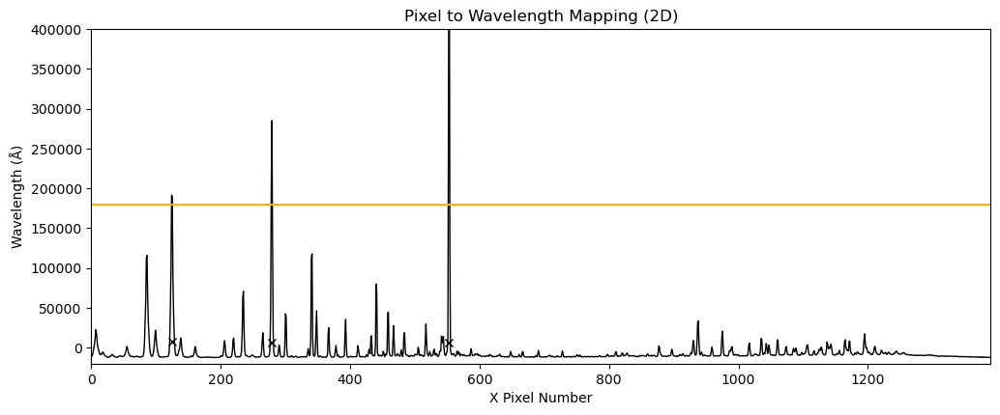

/home/jovyan/AST326/lab2/32/Ne_cal_tests.ipynb:330: RankWarning: Polyfit may be poorly conditioned
  "\n",


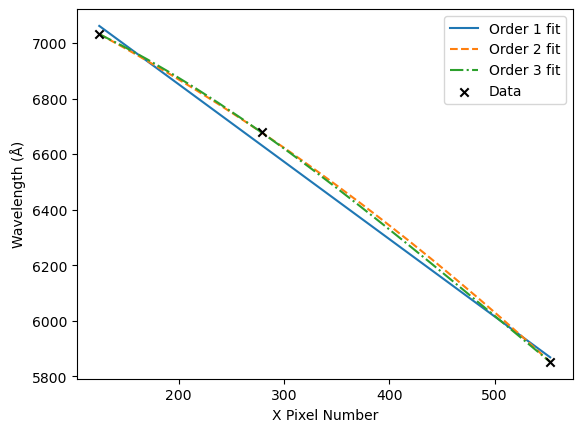

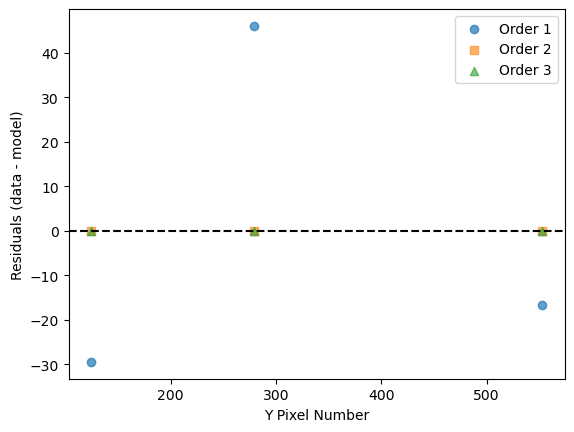

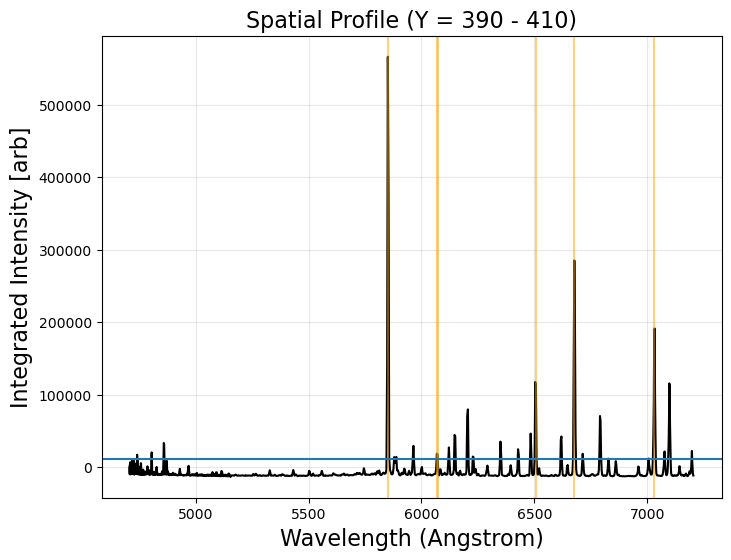

[   7   86   99  124  138  220  235  265  279  300  341  348  367  393
  433  440  459  467  484  517  541  544  553  938  975 1195]
[7198.34004216 7098.26962621 7077.16461268 7033.21412627 7006.75019719
 6827.7921343  6791.09305304 6714.51145829 6677.42539173 6620.32539404
 6504.31335439 6483.97422822 6428.08083607 6350.14267988 6227.6063059
 6205.90361923 6146.70153712 6121.66658504 6068.30910409 5964.39402714
 5888.82988694 5879.39897608 5851.13690886 4858.5370697  4804.78614211
 4740.44436558]
26
[ 335  429  451  479  505  523  530  539  565  568  587  648  667  691
  728  811  897  943  959  986 1085 1089 1117 1125 1128 1140 1156 1169
 1184 1198 1221 1244]
[6521.63120343 6239.97778556 6171.67668393 6084.02136241 6002.20551032
 5945.49004392 5923.44342595 5895.1195973  5813.54311143 5804.16365585
 5744.97777106 5558.66294425 5502.21694172 5432.30276125 5328.06933397
 5114.04624698 4929.79398118 4850.66712916 4826.74108063 4790.87227507
 4712.86882263 4711.63886298 4707.54617786 470

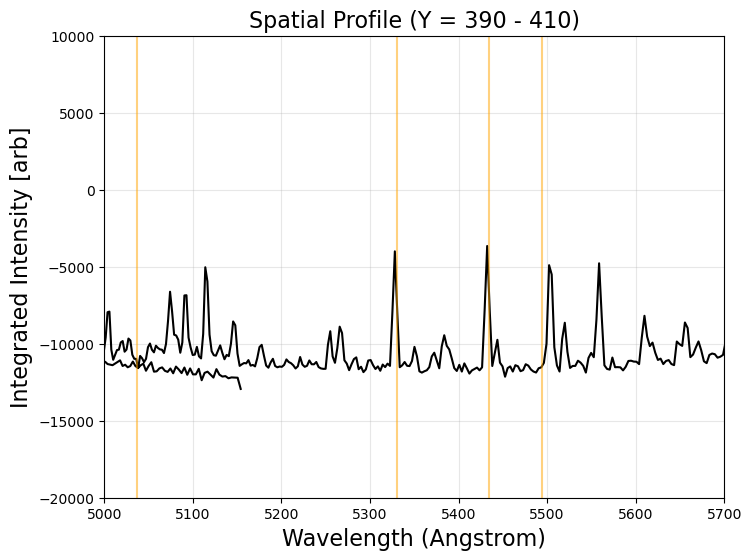

[5037, 5331, 5434, 5494, 5748]


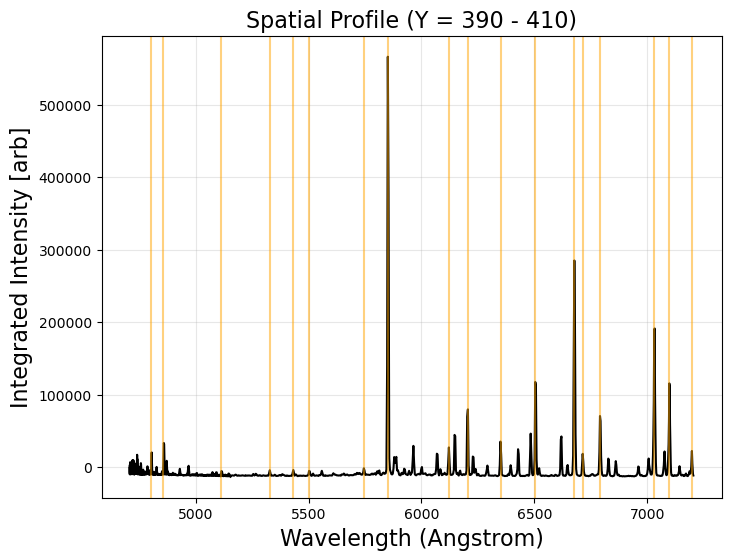

Sum of absolute residuals:
1st:	1052.8242705690373
3rd:	202.47448804726992
5th:	207.20706731198425
7th:	195.89224616191223
9th:	112.91143544824172
11th:	57.87124772659445
13th:	30.181477864791304
15th:	23.55343552863269

[ 3.04993682e-06 -4.79494946e-03 -6.74205035e-01  7.17047697e+03]
[2.27641875e-07 3.43774806e-04 1.45845408e-01 1.71641842e+01]


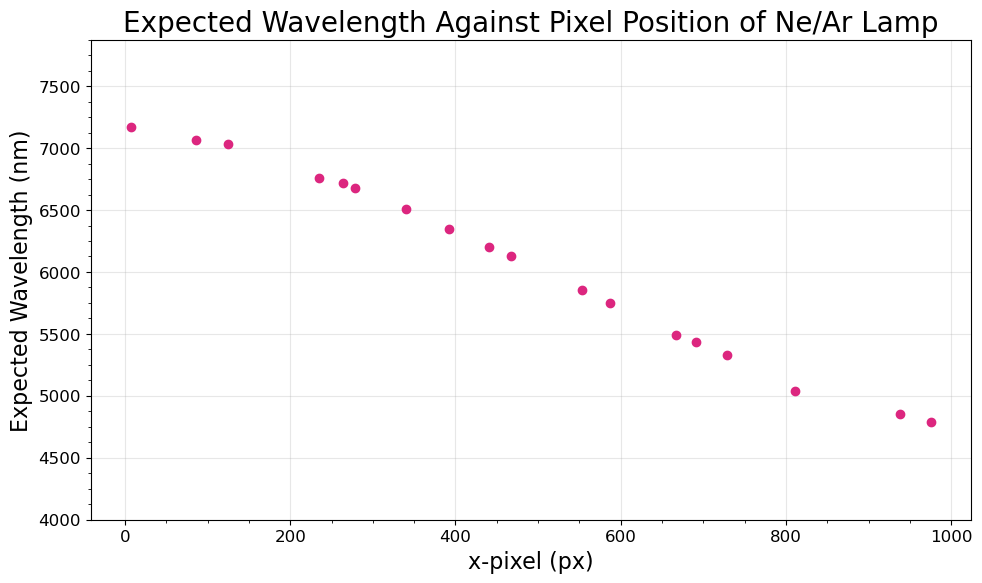

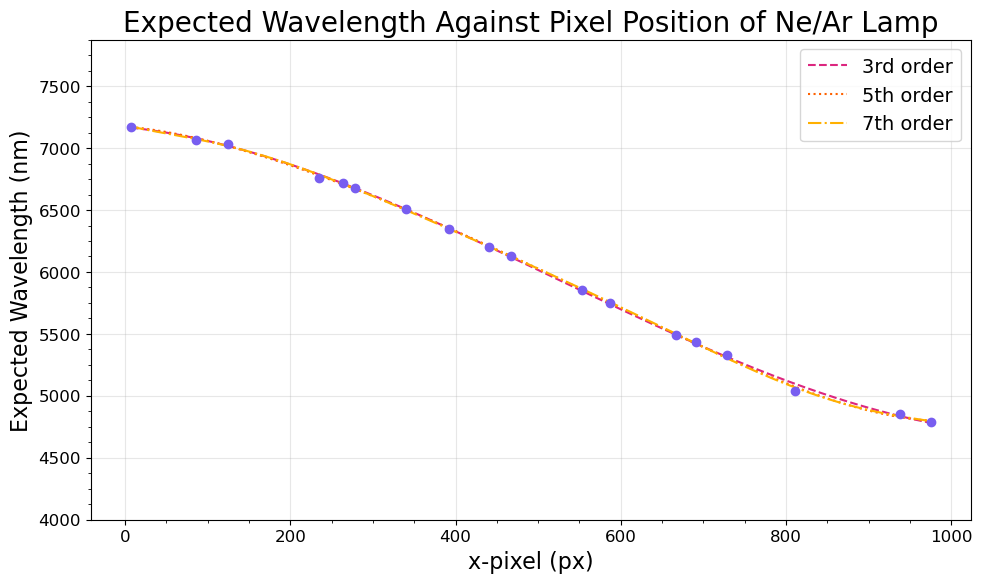

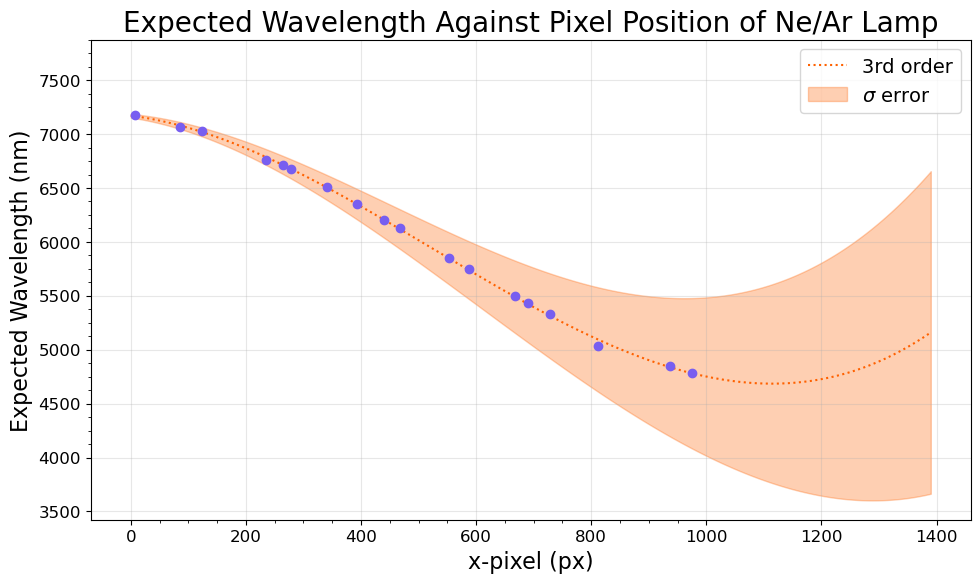

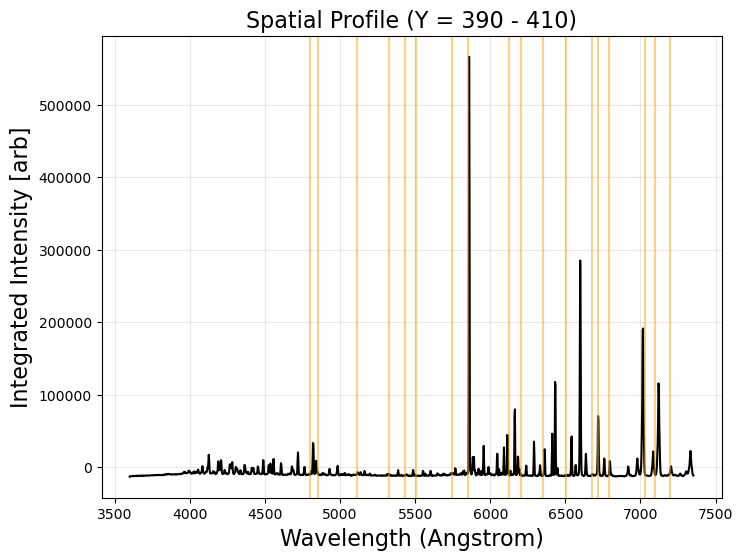

[124.29236986 278.82246524 552.75552329 975.11068652 937.27347764
 467.06644151 440.55807772 392.53799332 340.42316642 264.38510792
 234.525407    85.72728304   7.0725218  811.15955244 727.99445921
 691.00370382 667.15561799 587.0314017 ]
[ 3.17056261e-06 -4.97149257e-03 -6.16481424e-01  7.17271020e+03]
[3.49261938e-07 5.90196064e-04 2.99260454e-01 4.49377234e+01]


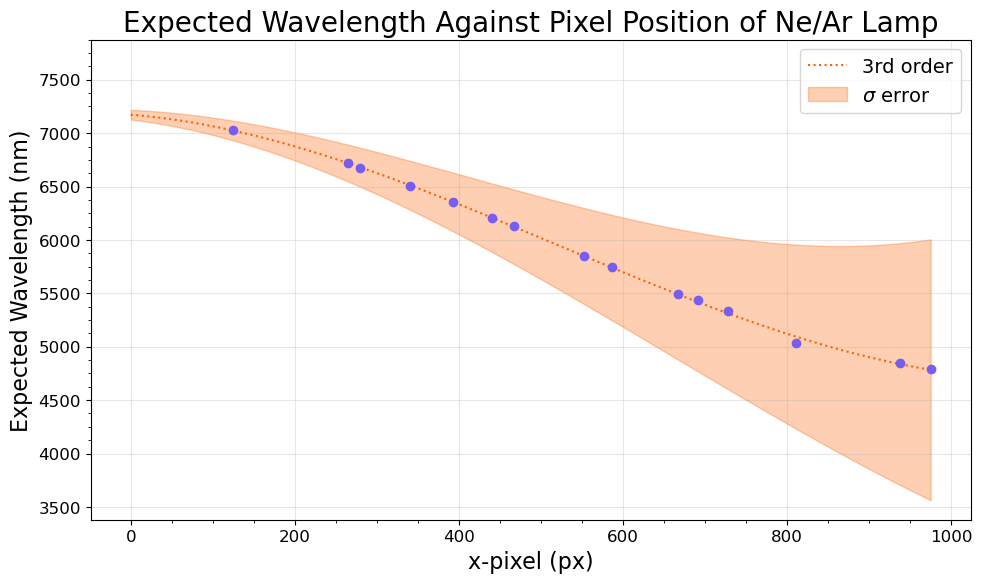

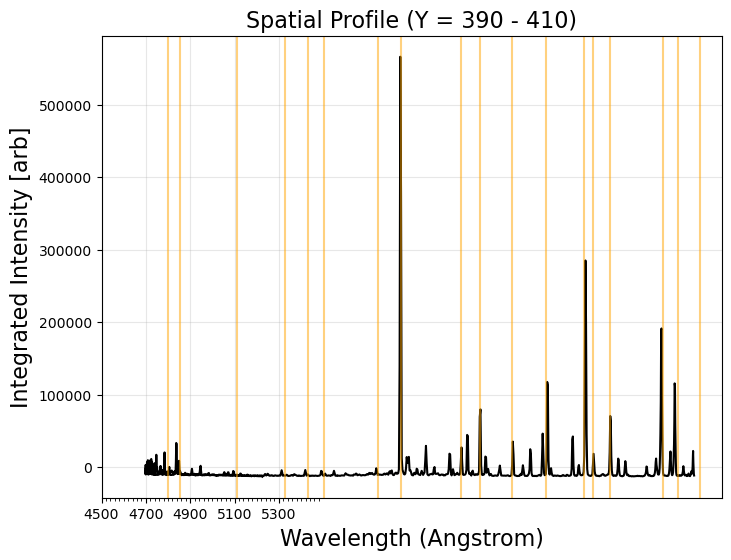

Calibration Equation (Cubic 15-point):
(Wavelength =
 3.2e-06 +/- 3e-07)x^3
-0.0049715 +/- 0.0005902)x^2
-0.6164814 +/- 0.2992605)x
+7172.7101965 +/- 44.9377234)
[7032, 6678, 5852, 4788, 4852, 6128, 6205, 6351, 6506, 6717, 6759, 7067, 7174, 5037, 5331, 5434, 5494, 5748]


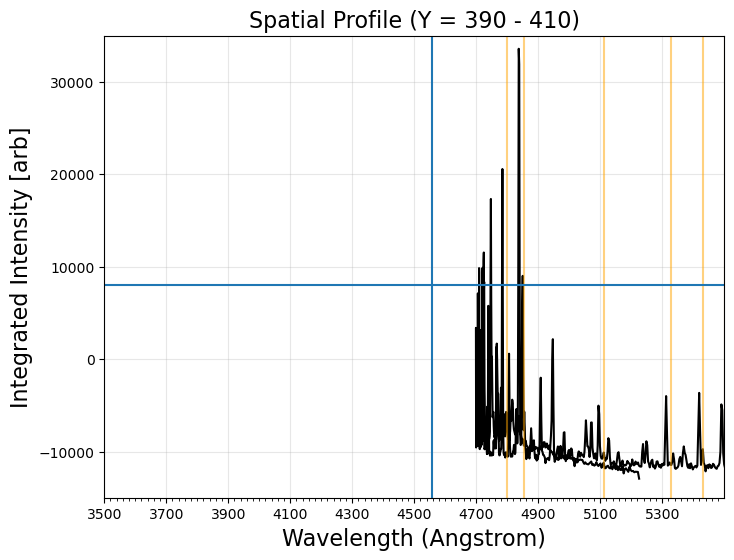

[ 124.29236986  278.82246524  552.75552329  975.11068652  937.27347764
  467.06644151  440.55807772  392.53799332  340.42316642  264.38510792
  811.15955244  727.99445921  691.00370382  667.15561799  587.0314017
 1195.12487363    7.0725218 ]
[7032.    6678.    5852.    4715.    4788.    6128.    6205.    6351.
 6506.    6717.    5037.    5331.    5434.    5494.    5748.    4400.986
 7174.   ]
[ 2.29314982e-06 -3.87273592e-03 -9.74103245e-01  7.19444045e+03]
[1.12281551e-07 2.04549789e-04 1.05687325e-01 1.59676536e+01]
[ 124.29236986  278.82246524  552.75552329  975.11068652  937.27347764
  467.06644151  440.55807772  392.53799332  340.42316642  264.38510792
  811.15955244  727.99445921  691.00370382  667.15561799  587.0314017
 1195.12487363    7.0725218 ]


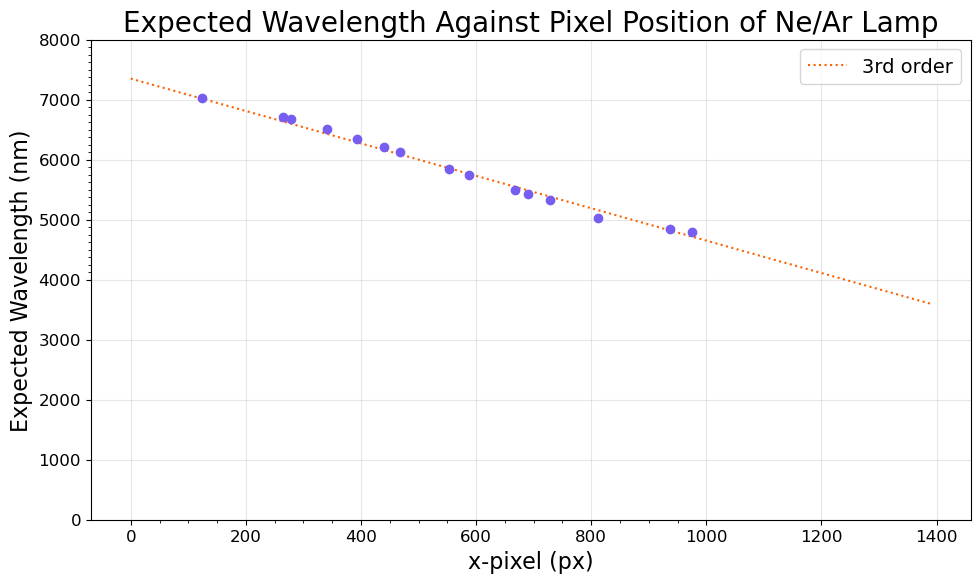

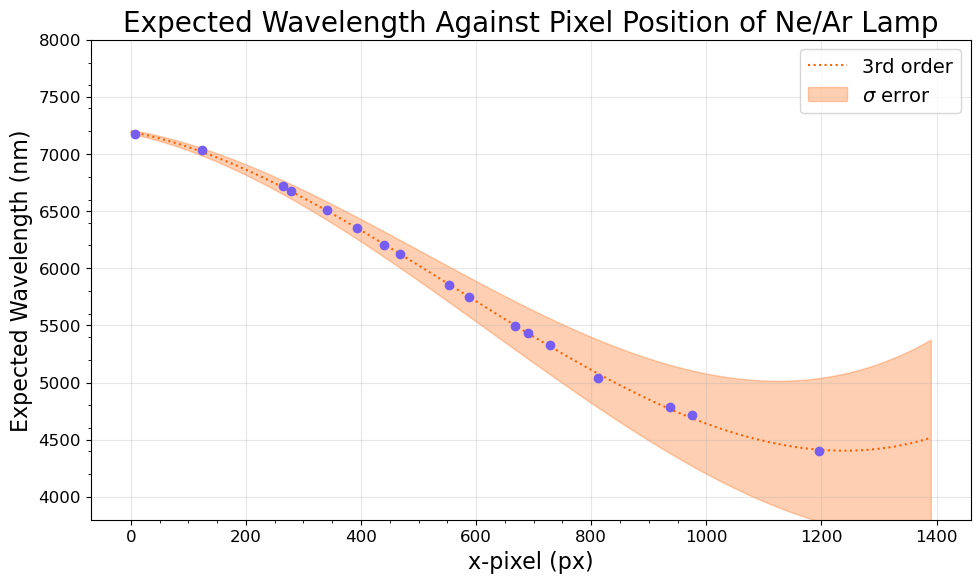

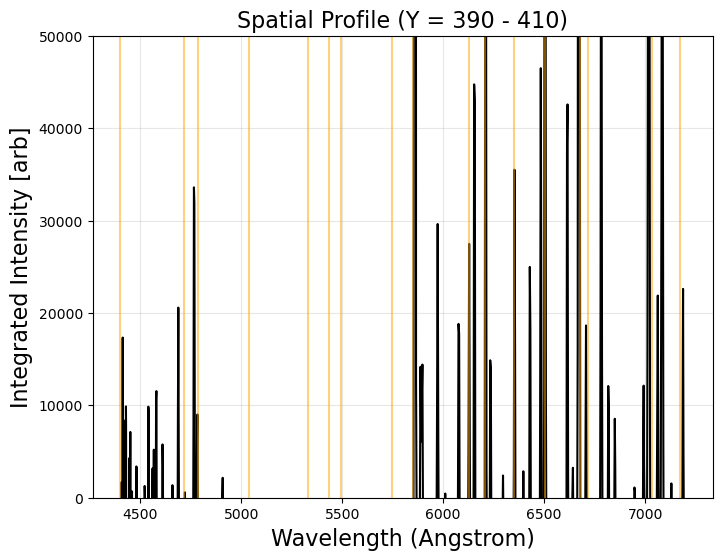

[7032.    6678.    5852.    4715.    4788.    6128.    6205.    6351.
 6506.    6717.    5037.    5331.    5434.    5494.    5748.    4400.986
 7174.   ]


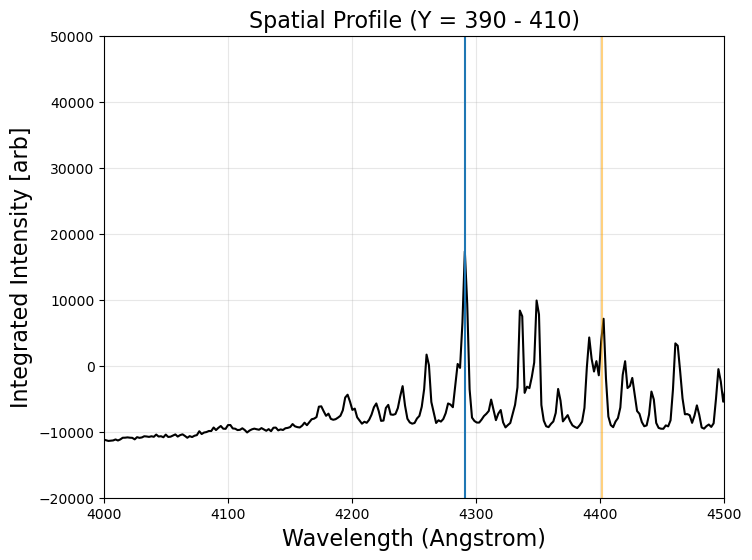

[7032.    6678.    5852.    4715.    4788.    6128.    6205.    6351.
 6506.    6717.    5037.    5331.    5434.    5494.    5748.    4400.986
 7174.   ]
[ 124.29236986  278.82246524  552.75552329  975.11068652  937.27347764
  467.06644151  440.55807772  392.53799332  340.42316642  264.38510792
  811.15955244  727.99445921  691.00370382  667.15561799  587.0314017
 1068.94875       7.0725218  1195.12487363]


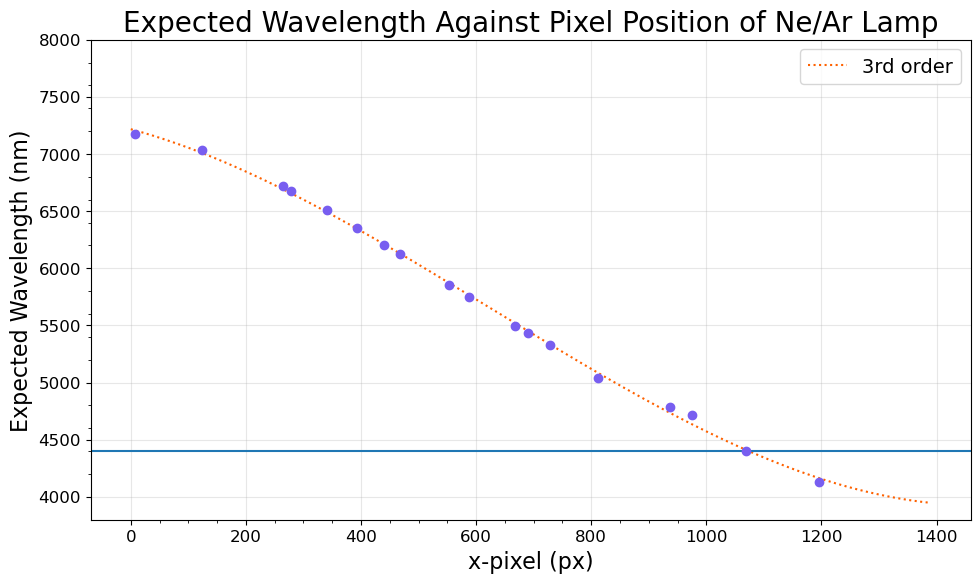

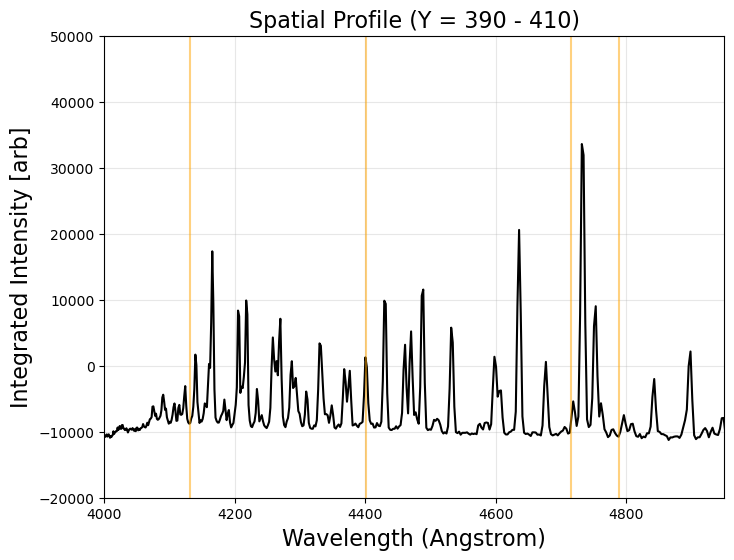

[7032.    6678.    5852.    4715.    4788.    6128.    6205.    6351.
 6506.    6717.    5037.    5331.    5434.    5494.    5748.    4400.986
 7174.    4131.   ]
[ 124.29236986  278.82246524  552.75552329  975.11068652  937.27347764
  467.06644151  440.55807772  392.53799332  340.42316642  264.38510792
  811.15955244  727.99445921  691.00370382  667.15561799  587.0314017
 1068.94875       7.0725218  1195.12487363]


[7032. 6678. 5852. 4590. 6128. 6205. 6351. 6506. 6717. 5037. 5331. 5434.
 5494. 5748. 7174. 4131.]
[ 124.29236986  278.82246524  552.75552329  975.11068652  467.06644151
  440.55807772  392.53799332  340.42316642  264.38510792  811.15955244
  727.99445921  691.00370382  667.15561799  587.0314017     7.0725218
 1195.12487363]
[ 1.81073881e-06 -3.40647245e-03 -1.07732975e+00  7.19620800e+03]
[8.90634575e-08 1.62556978e-04 8.27938375e-02 1.22201227e+01]
[ 124.29236986  278.82246524  552.75552329  975.11068652  467.06644151
  440.55807772  392.53799332  340.42316642  264.38510

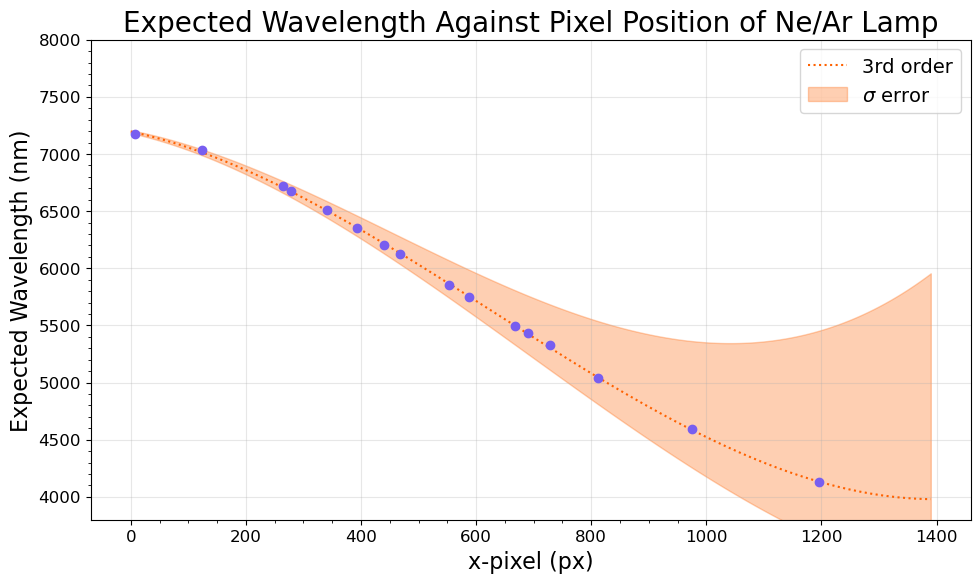

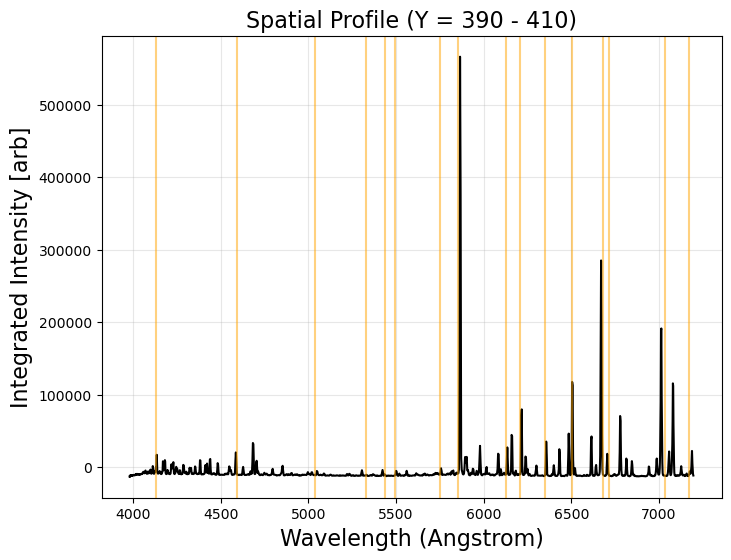

[7032. 6678. 5852. 4590. 6128. 6205. 6351. 6506. 6717. 5037. 5331. 5434.
 5494. 5748. 7174. 4131.]
[ 124.29236986  278.82246524  552.75552329  975.11068652  467.06644151
  440.55807772  392.53799332  340.42316642  264.38510792  811.15955244
  727.99445921  691.00370382  667.15561799  587.0314017     7.0725218
 1195.12487363]
[ 124.29236986  278.82246524  552.75552329  975.11068652  467.06644151
  440.55807772  392.53799332  340.42316642  264.38510792  811.15955244
  587.0314017     7.0725218  1195.12487363]
[7032. 6678. 5852. 4590. 6128. 6205. 6351. 6506. 6717. 5037. 5748. 7174.
 4131.]
[ 2.09715989e-06 -3.88628272e-03 -9.09082337e-01  7.18750847e+03]
[5.47900155e-08 9.71985946e-05 4.72734060e-02 6.84129516e+00]
[ 124.29236986  278.82246524  552.75552329  975.11068652  467.06644151
  440.55807772  392.53799332  340.42316642  264.38510792  811.15955244
  587.0314017     7.0725218  1195.12487363]


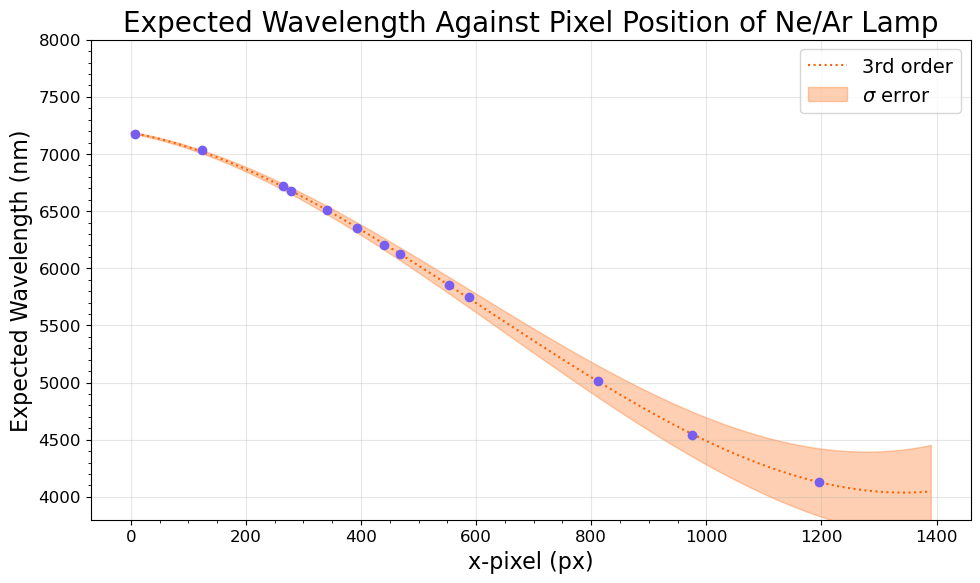

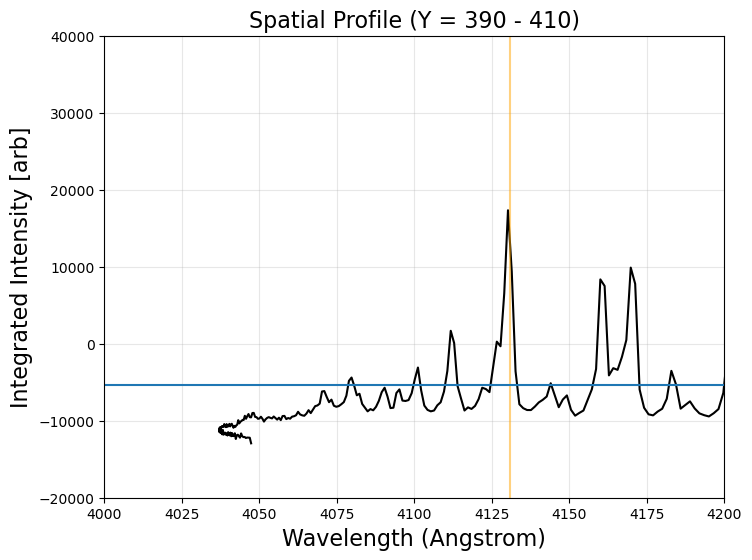

[ 2.07999104e-06 -3.86114361e-03 -9.18020470e-01  7.18804888e+03]
[4.63856971e-08 8.62982232e-05 4.38260410e-02 6.58655964e+00]
[4039.02988405 4038.62269768 4038.22402543 4037.83387979 4037.45227323
 4037.07921823 4036.71472727 4036.35881284 4036.01148741 4035.67276346
 4035.34265348 4035.02116993 4034.70832531 4034.40413209 4034.10860276
 4033.82174978 4033.54358565 4033.27412284 4033.01337383 4032.76135111
 4032.51806714 4032.28353442 4032.05776542 4031.84077262 4031.6325685
 4031.43316555 4031.24257623 4031.06081304 4030.88788845 4030.72381494
 4030.56860499 4030.42227108 4030.2848257  4030.15628131 4030.03665041
 4029.92594546 4029.82417896 4029.73136338 4029.6475112  4029.5726349
 4029.50674697 4029.44985987 4029.40198609 4029.36313812 4029.33332842
 4029.31256949 4029.30087379 4029.29825382 4029.30472205 4029.32029095
 4029.34497302 4029.37878073 4029.42172656 4029.47382298 4029.53508249
 4029.60551756 4029.68514067 4029.7739643  4029.87200092 4029.97926303
 4030.0957631  4030.22

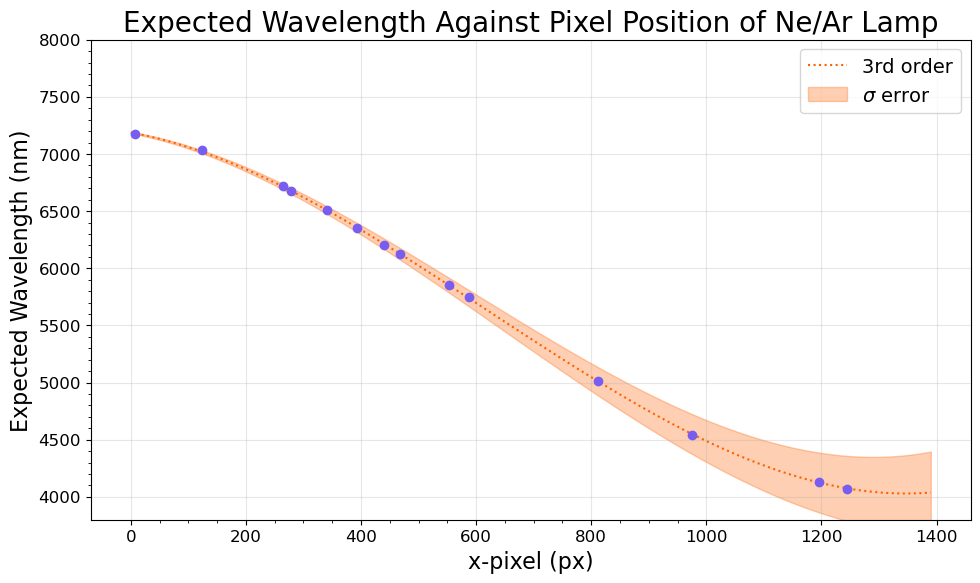

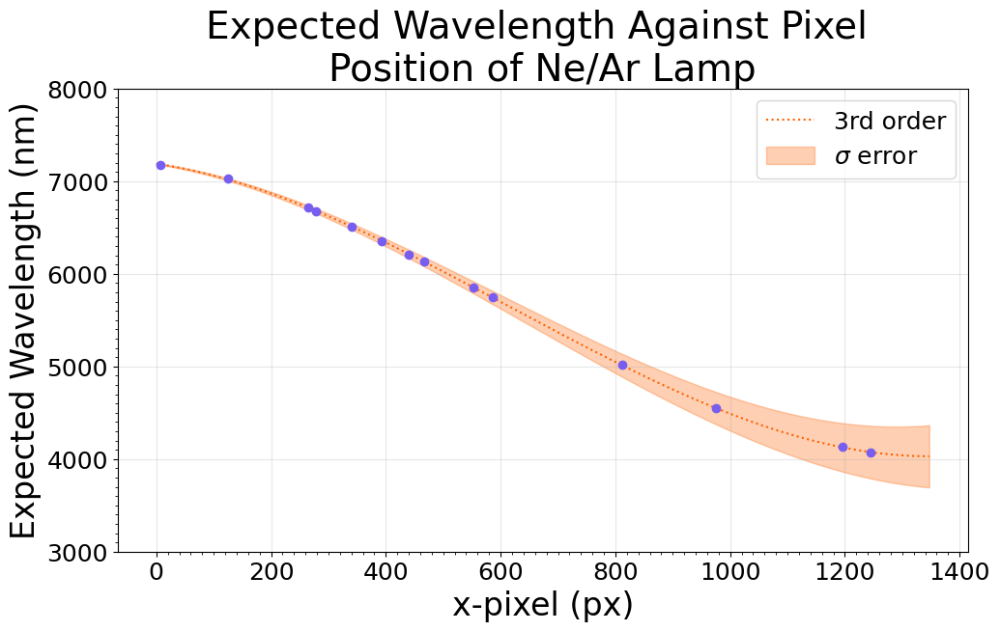

In [11]:
from ipynb.fs.full.Ne_cal_tests import get_calibration

In [12]:
spectra_range = f_cal(np.arange(0, ncols, 1))

print(spectra_range.shape)

(1391,)


[ 103180.37629976   96084.83537542   94495.10971728 ...  453104.64943257
  516053.13840676 -186023.4318542 ]
[ 46860.58927096  48817.7854819   49070.07826629 ... 638229.35401226
 662209.90116357 -84556.10538827]
[ 25001.09865409  26378.23399415  24910.3170006  ...  50073.84559405
  58505.1001028  558070.2955626 ]
[ 241714.76381212  237064.50271802  244611.9643489  ...   85083.10204751
   72495.45012738 -642626.40095087]
[  14999.7998513    15290.72477119   16641.36170812 ...  281453.20415467
  280336.93799258 1713670.40253566]


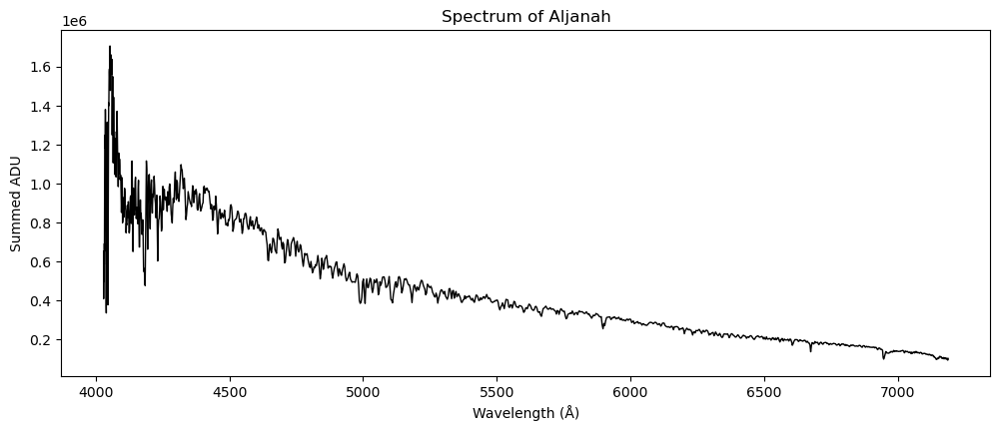

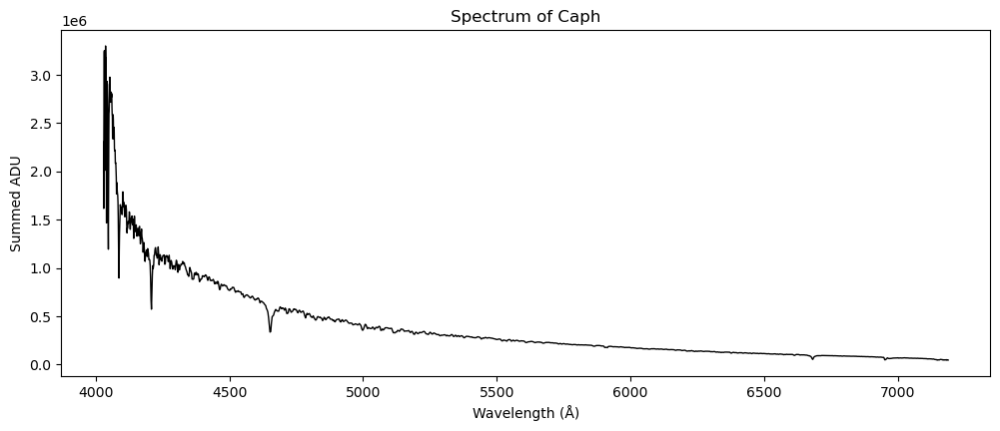

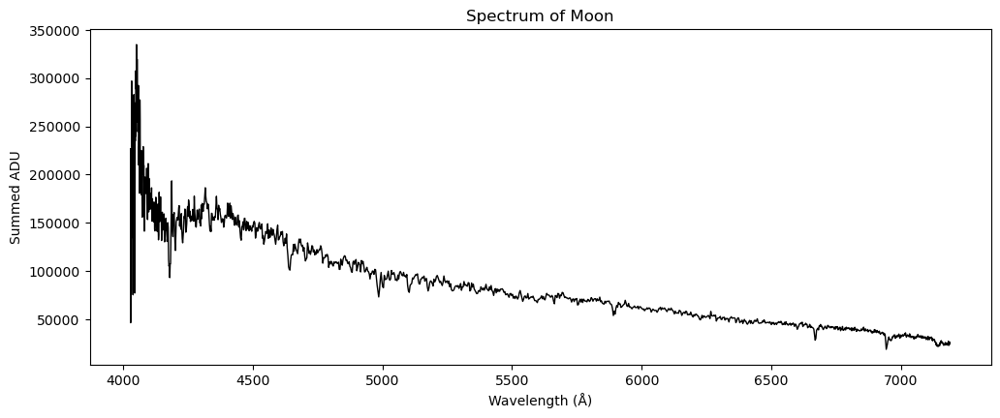

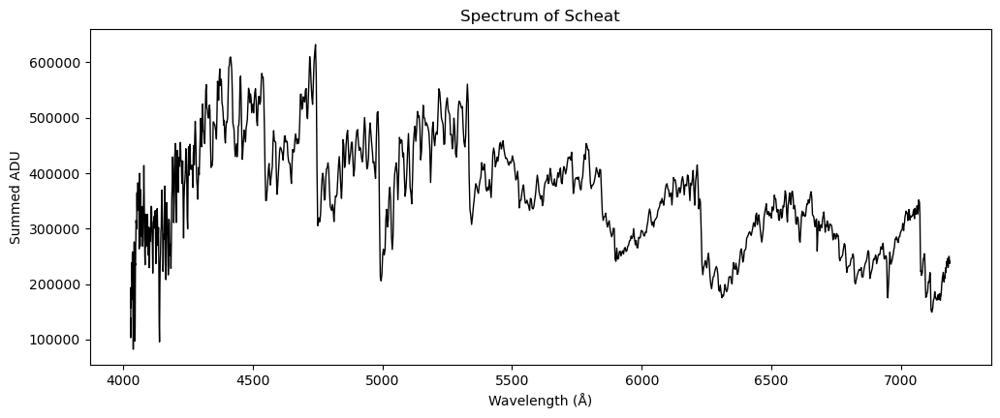

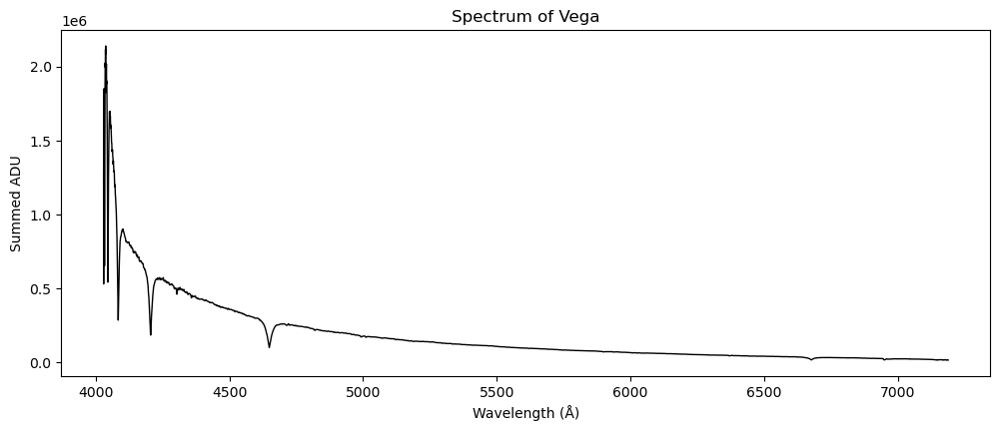

In [22]:
#He_lines = np.array([388.8648, 501.56783, 587.5621, 667.8151, 706.5190])

i = 0
# limit spectrum range to 1348 - wraps backward from then onward
for spectrum in nosky_spectra:
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(spectra_range[:1348], spectrum[:1348], color='k', lw=1, label=f"")
    ax.set(xlabel='Wavelength (Å)', ylabel=f"Summed ADU")
    #[ax.axvline(l*10) for l in He_lines]
    # plot H lines as a sanity check
    ax.set_title(f"Spectrum of {objs[i].capitalize()}")
    i+=1

Let's plot them all together! We'll use an offset to show them all on the same plot.

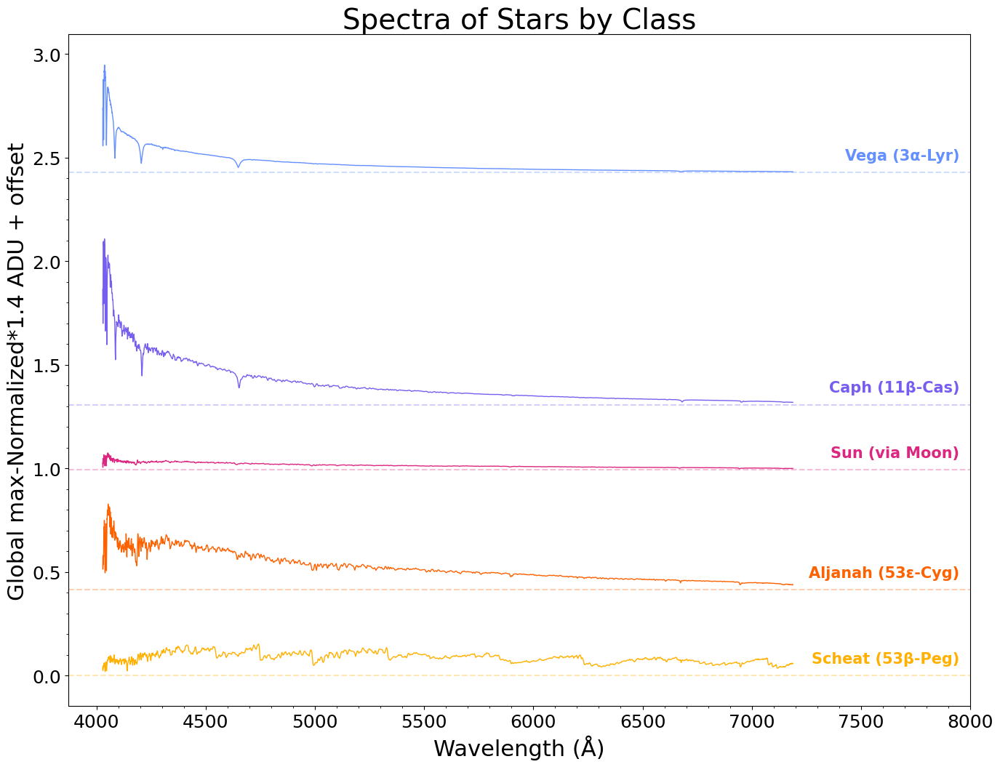

In [98]:
i = 0
fig, ax = plt.subplots(figsize=(16, 12))
ax.set_xlabel('Wavelength (Å)', fontsize=22)
ax.set_ylabel(f"Global max-Normalized*1.4 ADU + offset", fontsize=22)

# order spectra in star class order
ordered_spectra = np.array([nosky_spectra[3], nosky_spectra[0],
                            nosky_spectra[2], nosky_spectra[1],
                            nosky_spectra[4]])

normalized_spectra = np.array([0.8 * ordered_spectra[i] / np.max(ordered_spectra)
                               for i in range(len(ordered_spectra))])

ordered_objs = ["Scheat (53β-Peg)", "Aljanah (53ε-Cyg)", "Sun (via Moon)", "Caph (11β-Cas)", "Vega (3α-Lyr)"]

prev_max = 0
colours = ["#FFB000", "#FE6100", "#DC267F", "#785EF0", "#648FFF"]

# limit spectrum range to 1348 - wraps backward from then onward
for spectrum in normalized_spectra:
    ax.axhline(prev_max, ls="--", alpha=0.3, color=colours[i])
    ax.plot(spectra_range[:1348], spectrum[:1348] + prev_max, color=colours[i], lw=1, label=f"")
    #[ax.axvline(l*10) for l in He_lines]
    # plot H lines as a sanity check
    ax.set_title(f"Spectra of Stars by Class", fontsize=28)
    ax.text(7950, prev_max + 0.06, f"{ordered_objs[i]}", horizontalalignment='right', color=colours[i], size=15, weight='bold')

    prev_max += np.max(spectrum[:1348]) * 1.4
    
    if i == 2 or i == 0:
        prev_max += 0.2
    
    i+=1
    
    ax.set_xticks(np.arange(4000, 8100, 100), minor=True)
    ax.set_yticks(np.arange(0, 2.6, 0.1), minor=True)
    ax.tick_params(labelsize=18)